<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-15/lab-080-rbm-quantum-state.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 080. A restricted Boltzmann machine as the wave function of a spin chain

This notebook is the first of the two notebooks of Lecture 15, and Lab 081 follows it. The notebook needs the state of $N$ spins as a table of amplitudes, one for every bit string, and operators that act on one site of the chain, which the lecture builds on two spins in its part on a chain of quantum spins and which Sections 2 and 3 write out again. It also needs the restricted Boltzmann machine (RBM) of Lecture 14, with visible and hidden units, an energy and a Boltzmann weight, which Section 4 restates before changing it, and sampling as the drawing of configurations with given probabilities, which Section 6 builds on two spins.

A pure state of $N$ spins is a table of $2^N$ amplitudes, one for every bit string, and for fifty spins no computer can store it. In this notebook a neural network replaces the table by a rule with few parameters that returns one amplitude for a given bit string. The network is the RBM. In the energy-based models the Boltzmann weight summed over the hidden units gave the probability of a visible configuration. Here the same sum is read as the amplitude of a spin configuration. This use of the network was introduced in Ref. [1], where the resulting wave function is called a neural quantum state.

We take the open transverse-field Ising chain with $N=12$ spins at the critical field $g=J$. We build the amplitude of the network and the couplings that its hidden units create between the spins, write the energy and every Pauli string as an average of a local value over snapshots, and estimate these averages from snapshots sampled from a network with twelve hidden units. The parameters of this network are given. They were prepared in advance, outside this notebook, by lowering the energy of the network, and this notebook loads them from a file. With twelve spins all $4096$ configurations can still be summed exactly, and these exact sums serve only as a check of every sampled quantity.

The core route consists of Sections 1 to 6 and took 18 seconds in the recorded run. It ends with the line "The core route ends here." Section 7 summarises the notebook, and Section 8 collects exercises.

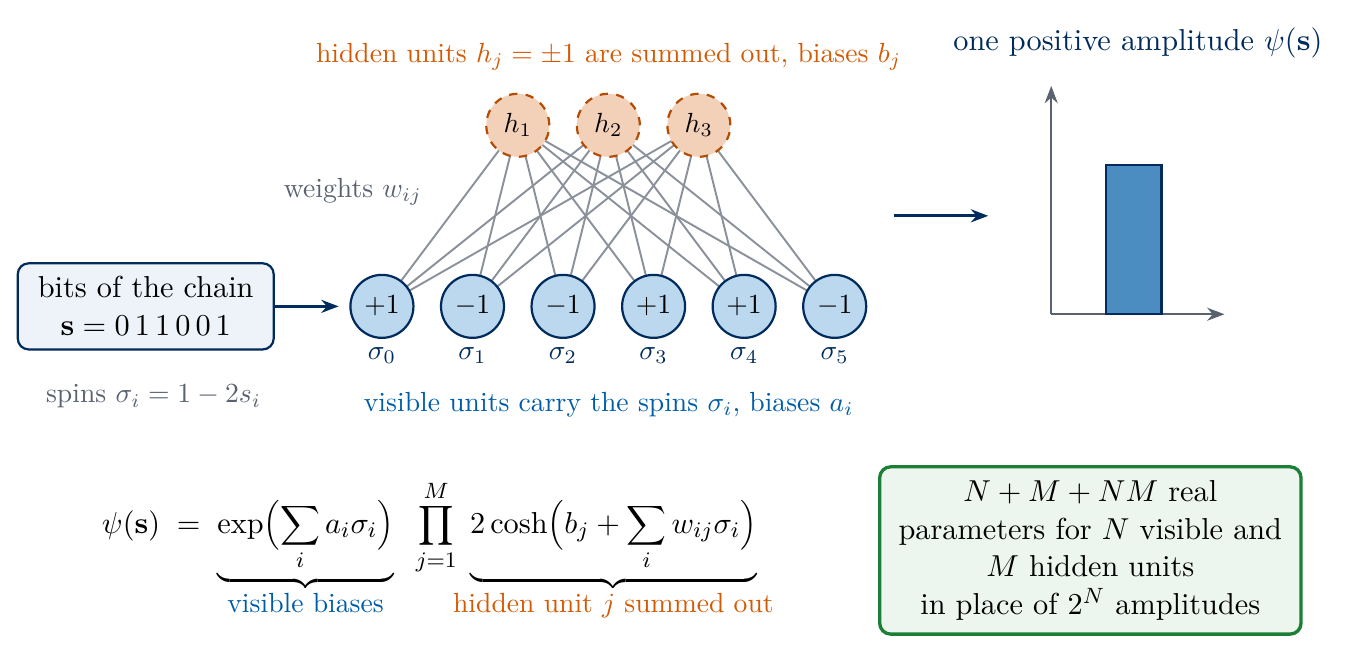

The sketch shows the rule of this notebook for six sites. The bits of a configuration become spins $\sigma_i=\pm1$ on the visible units, every hidden unit is coupled to every visible unit, the hidden units are summed out and one positive number comes out. Section 4 derives the formula at the bottom.

## 1. Libraries

NumPy and SciPy build the Hamiltonian as a sparse matrix and find its ground state. JAX evaluates the network for many configurations at once and runs the Metropolis chains. All calculations run in double precision on the CPU, and the GPU is never used. Matplotlib draws the figures. Cells or parts of cells whose first comment reads "bookkeeping", "check" or "figure" save files, test a formula or draw plots, and they may be skipped on a first reading.

In [ ]:
# data files of this notebook, downloaded from the course repository if they are not in ./data
import os, urllib.request
os.makedirs("data", exist_ok=True)
for name in ['rbm_tfim_N12_M12_params.npz']:
    if not os.path.exists(f"data/{name}"):
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/main/notebooks/lecture-15/data/{name}", f"data/{name}")

In [1]:
# Bookkeeping cell (can be skipped on a first reading): imports, CPU-only JAX, thread limit, figure style and helpers.
import os
os.environ["JAX_PLATFORMS"] = "cpu"            # the GPU is never used; every array of this notebook is small
os.environ.setdefault("OMP_NUM_THREADS", "4")   # takes effect only if NumPy is not yet loaded (execute_classroom.py fixes one OpenBLAS thread)
os.environ.setdefault("XLA_FLAGS", "--xla_cpu_multi_thread_eigen=true intra_op_parallelism_threads=4")
import json, time, itertools
from pathlib import Path
import numpy as np
import scipy.sparse as sparse
import scipy.sparse.linalg as sparse_linalg
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

jax.config.update("jax_enable_x64", True)       # double precision, needed for energy errors of order 1e-6
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
DATA = Path("data")                              # the parameters of the trained network (Section 6)
RES = Path("classroom_results"); RES.mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.labelsize": 11, "xtick.labelsize": 11, "ytick.labelsize": 11,
                     "legend.fontsize": 11, "figure.figsize": (4.6, 3.1), "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42, "ps.fonttype": 42})
# one palette for the whole notebook: exact results black, RBM orange, a second data set blue,
# sampled quantities purple, auxiliary lines grey
COL = dict(exact="black", rbm="#D35A05", blue="#005CA7", sampled="#6A3D9A", grey="#9AA0A6")
SLIDE_RC = {"font.size": 12.5, "axes.labelsize": 12.5, "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 12}

# --- bookkeeping (may be skipped): saving figures and numbers ---
def save(fig, name):
    fig.savefig(FIG / f"{name}.pdf"); fig.savefig(FIG / f"{name}.png", dpi=150)
def panels(name, draws):
    # notes: panels side by side at 7.0 x 2.9 in, 11 pt; slides: every panel also as its own file at 4.6 x 3.1 in
    fig, axes = plt.subplots(1, len(draws), figsize=(7.0, 2.9))
    for ax, draw, lab in zip(axes, draws, "abcdef"):
        draw(ax)
        ax.set_title(f"({lab})", loc="left", fontsize=11)
    fig.tight_layout(); save(fig, name); plt.show()
    for draw, lab in zip(draws, "abcdef"):
        with plt.rc_context(SLIDE_RC):
            single, ax = plt.subplots(figsize=(4.6, 3.1))
            draw(ax)
            single.tight_layout(); save(single, f"{name}_{lab}"); plt.close(single)
def one_panel(name, draw):
    # a single-panel figure, one file at 4.6 x 3.1 in with 12.5 pt fonts (readable in the notes and on a slide)
    with plt.rc_context(SLIDE_RC):
        fig, ax = plt.subplots(figsize=(4.6, 3.1))
        draw(ax)
        fig.tight_layout(); save(fig, name); plt.show()
def sci(x, digits=1):
    # a number as LaTeX scientific notation, e.g. 2.1\times10^{-3}
    m, e = f"{x:.{digits}e}".split("e")
    return f"{m}\\times10^{{{int(e)}}}"
started = time.perf_counter()
NUMBERS = {}                                    # every number quoted in the text, written to a macro file at the end
key = jax.random.PRNGKey(80)                    # random numbers of the Monte Carlo sampling
print("JAX", jax.__version__, "| devices:", jax.devices())

JAX 0.11.0 | devices: [CpuDevice(id=0)]


## 2. Bits and spins

A basis state of $N$ spins is labelled by a bit string $\mathbf s=s_0s_1\dots s_{N-1}$ with $s_i\in\{0,1\}$. Site 0 is the most significant bit, so the string is the binary form of the basis index $k=\sum_i s_i2^{N-1-i}$. A state is the superposition
$$|\psi\rangle=\sum_{\mathbf s}\psi(\mathbf s)\,|\mathbf s\rangle , \tag{1}$$
with one amplitude $\psi(\mathbf s)$ per bit string. The Hamiltonian and the network are written with spins. On a basis state the operator $\hat\sigma^z_i$ has the eigenvalue
$$\sigma_i=1-2s_i\in\{+1,-1\},\qquad \hat\sigma^z_i|\mathbf s\rangle=\sigma_i|\mathbf s\rangle , \tag{2}$$
so the bit 0 is the spin up, $\sigma_i=+1$, and the bit 1 is the spin down, $\sigma_i=-1$. Throughout the notebook the letter $s$ denotes the bit and $\sigma$ the spin. A measurement of all spins along $z$ returns one bit string $\mathbf s$, and we call such a bit string a snapshot. We list the eight bit strings of three sites with their spins, in the order of the index $k$.

In [2]:
def bit_table(N):
    # row k holds the bits (s_0, ..., s_{N-1}) of basis state k; qubit 0 is the most significant bit
    # itertools.product runs through 00..0, 00..1, ... in the order of k; result shape (2^N, N)
    return np.array(list(itertools.product([0, 1], repeat=N)))

def spins(bits):
    # equation (2): sigma_i = 1 - 2 s_i, so bit 0 -> +1 and bit 1 -> -1 (the eigenvalue of sigma^z_i)
    return 1 - 2 * bits

B3 = bit_table(3)                               # shape (8, 3)
print(" k   bits s_0 s_1 s_2   spins sigma_0 sigma_1 sigma_2")
for k in range(8):
    print(f" {k}      {B3[k][0]}   {B3[k][1]}   {B3[k][2]}          {spins(B3[k])[0]:+d}      {spins(B3[k])[1]:+d}      {spins(B3[k])[2]:+d}")
assert bit_table(4)[5].tolist() == [0, 1, 0, 1]  # k = 5 = 0*8 + 1*4 + 0*2 + 1*1

 k   bits s_0 s_1 s_2   spins sigma_0 sigma_1 sigma_2
 0      0   0   0          +1      +1      +1
 1      0   0   1          +1      +1      -1
 2      0   1   0          +1      -1      +1
 3      0   1   1          +1      -1      -1
 4      1   0   0          -1      +1      +1
 5      1   0   1          -1      +1      -1
 6      1   1   0          -1      -1      +1
 7      1   1   1          -1      -1      -1


## 3. Transverse-field Ising chain as a sum of Pauli strings

The transverse-field Ising chain [2] is a row of $N$ spins in which neighbours prefer to be parallel along $z$ and a field $g$ along $x$ flips them,
$$\hat{\mathcal H}=-J\sum_{i=0}^{N-2}\hat\sigma^z_i\hat\sigma^z_{i+1}-g\sum_{i=0}^{N-1}\hat\sigma^x_i . \tag{3}$$
The chain is open, so the first sum has $N-1$ bonds. We set $J=1$ as the unit of energy and study $N=12$ at the critical field $g=J$. In the infinite chain this field separates the ordered phase at $g<J$, where the spins align along $z$, from the paramagnet at $g>J$, where they point along $x$.

Each term of equation (3) is a Pauli string, a product of Pauli matrices on some sites and the unit matrix on all others. The string $\hat\sigma^z_i\hat\sigma^z_{i+1}$ acts on two neighbouring sites and $\hat\sigma^x_i$ on one. The energy of any state is therefore a weighted sum of expectation values of strings,
$$\mathcal E=\langle\hat{\mathcal H}\rangle=-J\sum_{i=0}^{N-2}\langle\hat\sigma^z_i\hat\sigma^z_{i+1}\rangle-g\sum_{i=0}^{N-1}\langle\hat\sigma^x_i\rangle , \tag{4}$$
and the whole Hamiltonian enters the model through these $2N-1$ expectation values. The two kinds of strings act differently on a basis state. The string $\hat\sigma^z_i\hat\sigma^z_{i+1}$ multiplies $|\mathbf s\rangle$ by the number $\sigma_i\sigma_{i+1}$, which is $+1$ when the neighbours agree and $-1$ when they disagree. The string $\hat\sigma^x_i$ flips bit $i$, so it maps $|\mathbf s\rangle$ to $|\mathbf s^{(i)}\rangle$, the configuration in which bit $i$ is flipped. The only nonzero matrix elements of $\hat{\mathcal H}$ in the basis of bit strings are therefore
$$\langle\mathbf s|\hat{\mathcal H}|\mathbf s\rangle=-J\sum_{i=0}^{N-2}\sigma_i\sigma_{i+1},\qquad \langle\mathbf s^{(i)}|\hat{\mathcal H}|\mathbf s\rangle=-g ,\quad i=0,\dots,N-1 , \tag{5}$$
which gives $N+1$ nonzero elements in every row. The diagonal element is the classical Ising energy of the configuration.

All off-diagonal elements are negative or zero, and this fixes the sign of the ground state. For a state with real amplitudes the energy splits into a diagonal and an off-diagonal sum,
$$\langle\psi|\hat{\mathcal H}|\psi\rangle=\sum_{\mathbf s}\langle\mathbf s|\hat{\mathcal H}|\mathbf s\rangle\,\psi(\mathbf s)^2+\sum_{\mathbf s\neq\mathbf s'}\langle\mathbf s|\hat{\mathcal H}|\mathbf s'\rangle\,\psi(\mathbf s)\psi(\mathbf s') . \tag{6}$$
Replacing every amplitude by its modulus leaves the norm and the diagonal sum unchanged. Each term of the off-diagonal sum is a non-positive matrix element times $\psi(\mathbf s)\psi(\mathbf s')$, so the sum can only decrease when all these products become positive. A ground state with non-negative amplitudes therefore exists. A sequence of single flips connects every bit string with every other, and the Perron–Frobenius theorem then makes the ground state unique with all amplitudes strictly positive. A wave function with positive amplitudes is therefore sufficient for this Hamiltonian.

The probability of finding the snapshot $\mathbf s$ in a measurement along $z$ is given by the Born rule,
$$p(\mathbf s)=\frac{\psi(\mathbf s)^2}{Z},\qquad Z=\sum_{\mathbf s}\psi(\mathbf s)^2=\langle\psi|\psi\rangle , \tag{7}$$
for real amplitudes. We measure the order along $z$ by the correlation between the first spin and the spin at distance $r$,
$$C(r)=\langle\hat\sigma^z_0\hat\sigma^z_r\rangle=\sum_{\mathbf s}p(\mathbf s)\,\sigma_0\sigma_r ,\qquad r=1,\dots,N-1 , \tag{8}$$
which needs only the probabilities of the snapshots.

We build the matrix (5) as a sparse $4096\times4096$ array, check it against Kronecker products of Pauli matrices for four sites, and find the ground state with the Lanczos solver of SciPy [3]. Its energy $\mathcal E_0$ is the reference for everything that follows.

In [3]:
N, J, g_c = 12, 1.0, 1.0                          # sites, coupling J (unit of energy), transverse field g = J
DIM = 2 ** N                                     # 4096 basis states

def flip_table(N):
    # FLIP[k, i] = index of bit string k with bit i flipped. Bit i carries the value 2^(N-1-i) in k,
    # so flipping it is the exclusive or (^) with that power of two. Shape (2^N, N).
    return np.arange(2 ** N)[:, None] ^ (1 << (N - 1 - np.arange(N)))[None, :]

def tfim_matrix(g, N, J=1.0):
    # equation (3) as a sparse 2^N x 2^N matrix with the matrix elements of equation (5):
    # diagonal  -J sum_i sigma_i sigma_{i+1};  -g between two bit strings that differ in exactly one bit
    sigma, flips = spins(bit_table(N)), flip_table(N)
    diagonal = -J * np.sum(sigma[:, :-1] * sigma[:, 1:], axis=1)           # shape (2^N,)
    rows = np.repeat(np.arange(2 ** N), N)                                 # row k repeated N times
    off_diagonal = sparse.csr_matrix((np.full(2 ** N * N, -g), (rows, flips.ravel())), shape=(2 ** N, 2 ** N))
    return (off_diagonal + sparse.diags(diagonal)).tocsr()

# check (may be skipped): for N = 4 the same matrix from Kronecker products of 2 x 2 Pauli matrices, qubit 0 leftmost
def kron_all(mats):
    out = np.ones((1, 1))
    for m in mats:
        out = np.kron(out, m)
    return out
I2, X, Z = np.eye(2), np.array([[0.0, 1.0], [1.0, 0.0]]), np.diag([1.0, -1.0])
H4 = -sum(kron_all([Z if q in (i, i + 1) else I2 for q in range(4)]) for i in range(3)) \
     - 0.7 * sum(kron_all([X if q == i else I2 for q in range(4)]) for i in range(4))
assert np.allclose(tfim_matrix(0.7, 4).toarray(), H4)

SIGMA = spins(bit_table(N))                      # all 4096 spin configurations, shape (4096, 12)
FLIP = flip_table(N)                             # shape (4096, 12)
DIAG = -J * np.sum(SIGMA[:, :-1] * SIGMA[:, 1:], axis=1)                    # diagonal of the matrix, shape (4096,)
S0SR = (SIGMA[:, :1] * SIGMA[:, 1:]).T           # row r-1 holds sigma_0 sigma_r of every configuration, shape (11, 4096)

def correlations(prob):
    # equation (8): C(r) = sum_s p(s) sigma_0 sigma_r for r = 1, ..., N-1; prob has shape (4096,)
    return S0SR @ prob

def exact_ground_state(g):
    # the two lowest eigenvalues of the sparse matrix by the Lanczos method of SciPy (eigsh)
    H = tfim_matrix(g, N)
    w, v = sparse_linalg.eigsh(H, k=2, which="SA")
    order = np.argsort(w); w, v = w[order], v[:, order]
    psi0 = v[:, 0] * np.sign(v[0, 0])            # overall sign fixed so that the first amplitude is positive
    return dict(H=H, E0=float(w[0]), gap=float(w[1] - w[0]), psi0=psi0, C=correlations(psi0 ** 2))

t0 = time.perf_counter()
EXACT = {g_c: exact_ground_state(g_c)}
ex = EXACT[g_c]
print(f"N = {N}, g = J: matrix of {DIM} x {DIM} with {ex['H'].nnz} nonzero elements, diagonalised in {time.perf_counter() - t0:.2f} s")
print(f"ground-state energy E_0 = {ex['E0']:.6f} J,  gap to the first excited state {ex['gap']:.4f} J")
print(f"smallest and largest amplitude of the ground state: {ex['psi0'].min():.2e}, {ex['psi0'].max():.2e}")
assert np.all(ex["psi0"] > 0)                    # every amplitude of the ground state is positive
print("C(r) for r = 1 ... 11:", np.round(ex["C"], 4))
NUMBERS.update(N=str(N), Dim=str(DIM), EZero=f"{ex['E0']:.4f}", Gap=f"{ex['gap']:.3f}",
               AmpMin=sci(ex["psi0"].min()), AmpMax=f"{ex['psi0'].max():.3f}", COne=f"{ex['C'][0]:.2f}", CLast=f"{ex['C'][-1]:.2f}")

N = 12, g = J: matrix of 4096 x 4096 with 53248 nonzero elements, diagonalised in 0.04 s
ground-state energy E_0 = -14.925971 J,  gap to the first excited state 0.2512 J
smallest and largest amplitude of the ground state: 7.07e-04, 2.54e-01
C(r) for r = 1 ... 11: [0.5076 0.3728 0.3023 0.2565 0.2231 0.1966 0.1739 0.1532 0.1327 0.1102
 0.0803]


The ground-state energy is $\mathcal E_0=-14.9260\,J$, with a gap of $0.251\,J$ to the first excited state. All 4096 amplitudes are positive, as the argument above states. The correlation function falls from $0.51$ at $r=1$ to $0.08$ at $r=11$. The printed lines and the figure labels follow the code and write $E$ and $E_0$ for the energies $\mathcal E$ and $\mathcal E_0$.

## 4. The RBM ansatz

The classical RBM of the energy-based models has $N$ visible units and $M$ hidden units. Every visible unit is coupled to every hidden unit by a weight, and there are no couplings inside a layer. The visible units carry biases $a_i$ and the hidden units biases $b_j$. The network assigns an energy $E(\mathbf v,\mathbf h)$ to every joint configuration of the two layers, and the probability of a visible configuration was the Boltzmann weight $e^{-E}$ summed over all hidden configurations and divided by the partition function. Reference [1] takes the same sum, without the division, as the amplitude of a spin configuration. The visible units become the twelve physical spins $\sigma_i=\pm1$ of the chain. We let the hidden units take the values $h_j=\pm1$ as well and write $w_{ij}$ for the weight between spin $i$ and hidden unit $j$, the letter of the lecture. The capital $W_{ij}$ of Lecture 14 coupled units with the values 0 and 1, and for spins it becomes $w_{ij}=W_{ij}/4$, as the lecture shows. The energy and the amplitude read
$$E(\boldsymbol\sigma,\mathbf h)=-\sum_i a_i\sigma_i-\sum_j b_jh_j-\sum_{i,j}\sigma_iw_{ij}h_j ,\qquad \psi(\mathbf s)=\sum_{\mathbf h}e^{-E(\boldsymbol\sigma,\mathbf h)} . \tag{9}$$
The sum runs over all $2^M$ hidden configurations $\mathbf h=(h_1,\dots,h_M)$, and the spins $\boldsymbol\sigma=(\sigma_0,\dots,\sigma_{N-1})$ follow from the bits by equation (2). The amplitude $\psi(\mathbf s)$ plays the role that the unnormalised Boltzmann weight of a visible configuration played in the classical RBM. The parameters $\boldsymbol\theta=(a,b,w)$ are real numbers in this notebook. In the code they are stored in a dictionary `p` with the keys `"a"`, `"b"` and `"W"`, and the array `p["W"]` of shape $(N,M)$ holds the weights $w_{ij}$.

The sum (9) has $2^M$ terms, but it factorises because the hidden units do not couple to each other. The same property made the hidden units independent of each other for a fixed visible configuration in the classical RBM, which is why their conditional probabilities could be sampled at once. Writing the Boltzmann weight as a product,
$$e^{-E(\boldsymbol\sigma,\mathbf h)}=e^{\sum_ia_i\sigma_i}\prod_{j=1}^{M}e^{h_j\,u_j(\mathbf s)} ,\qquad u_j(\mathbf s)=b_j+\sum_iw_{ij}\sigma_i , \tag{10}$$
shows that $h_j$ appears only in the $j$-th factor, together with the input $u_j$ of hidden unit $j$. The sum over all $\mathbf h$ is then a product of $M$ independent sums of two terms each, $\sum_{h_j=\pm1}e^{h_ju_j}=e^{u_j}+e^{-u_j}=2\cosh u_j$, and the amplitude becomes
$$\psi(\mathbf s)=\exp\Big(\sum_ia_i\sigma_i\Big)\prod_{j=1}^{M}2\cosh\Big(b_j+\sum_iw_{ij}\sigma_i\Big) . \tag{11}$$
The hyperbolic cosine comes from the two values $\pm1$ of a hidden unit. The classical RBM used hidden units with the values 0 and 1, for which the same sum gives
$$\sum_{h_j\in\{0,1\}}e^{h_ju_j}=1+e^{u_j} . \tag{12}$$
The two forms describe the same family of amplitudes after a change of the biases and weights, which Exercise 1 works out. For real parameters every factor of (11) is positive, so the amplitude is positive for every configuration, as the ground state of Section 3 requires. One amplitude costs of the order of $NM$ operations, and the network stores $N+M+NM$ parameters.

We check equation (11) against the explicit sum (9) for $N=4$ spins and $M=3$ hidden units with random real parameters, and count the parameters against the $2^N$ amplitudes.

N = 4, M = 3: 16 amplitudes, each a sum over 8 hidden configurations
largest relative difference between the product formula (11) and the explicit sum (9): 4.4e-16
  s = [0, 0, 0, 0], sigma = [1, 1, 1, 1]:  sum (9) = 33.955352,  product (11) = 33.955352
  s = [0, 1, 0, 1], sigma = [1, -1, 1, -1]:  sum (9) = 180.584467,  product (11) = 180.584467
  s = [1, 1, 1, 1], sigma = [-1, -1, -1, -1]:  sum (9) = 29.179615,  product (11) = 29.179615
all 16 amplitudes are positive; parameters N + M + N M = 19

   N   amplitudes 2^N   parameters for M = N   parameters for M = 2N
   4               16             24                   44
   8              256             80                  152
  12             4096            168                  324
  16        6.554e+04            288                  560
  32        4.295e+09           1088                 2144
  64        1.845e+19           4224                 8384


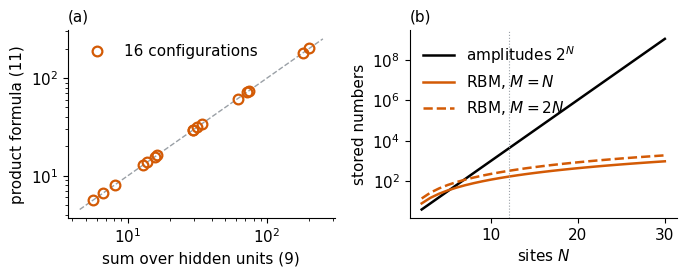

In [4]:
def rbm_amplitude(a, b, W, sigma):
    # equation (11): sigma has shape (..., N), a shape (N,), b shape (M,), W holds the weights w_ij, shape (N, M)
    u = b + sigma @ W                                       # inputs u_j(s) of the M hidden units, shape (..., M)
    return np.exp(sigma @ a) * np.prod(2 * np.cosh(u), axis=-1)

def rbm_amplitude_hidden_sum(a, b, W, sigma):
    # equation (9): the explicit sum of exp(-E) over all 2^M hidden configurations h, each h_j = +-1
    hidden = spins(bit_table(len(b)))                       # shape (2^M, M)
    return np.array([np.sum(np.exp(x @ a + hidden @ b + hidden @ (x @ W))) for x in sigma])

rng = np.random.default_rng(80)
N_small, M_small = 4, 3
a_s, b_s, W_s = 0.5 * rng.normal(size=N_small), 0.5 * rng.normal(size=M_small), 0.5 * rng.normal(size=(N_small, M_small))
S_small = spins(bit_table(N_small))                         # the 16 configurations of four spins
psi_formula = rbm_amplitude(a_s, b_s, W_s, S_small)         # 16 numbers from equation (11)
psi_sum = rbm_amplitude_hidden_sum(a_s, b_s, W_s, S_small)  # 16 numbers from equation (9), 8 terms each
check_hidden = float(np.max(np.abs(psi_formula / psi_sum - 1)))
assert check_hidden < 1e-12 and np.all(psi_formula > 0)
print(f"N = {N_small}, M = {M_small}: {2 ** N_small} amplitudes, each a sum over {2 ** M_small} hidden configurations")
print(f"largest relative difference between the product formula (11) and the explicit sum (9): {check_hidden:.1e}")
for k in (0, 5, 15):
    print(f"  s = {bit_table(N_small)[k].tolist()}, sigma = {S_small[k].tolist()}:  sum (9) = {psi_sum[k]:.6f},  product (11) = {psi_formula[k]:.6f}")
print(f"all {2 ** N_small} amplitudes are positive; parameters N + M + N M = {N_small + M_small + N_small * M_small}")
print("\n   N   amplitudes 2^N   parameters for M = N   parameters for M = 2N")
for n in (4, 8, 12, 16, 32, 64):
    print(f"  {n:2d}   {2.0 ** n:14.4g}   {n + n + n * n:12d}   {n + 2 * n + 2 * n * n:18d}")

# --- figure (drawing code may be skipped) ---
def draw_amp_a(ax):
    lim = [0.8 * psi_sum.min(), 1.25 * psi_sum.max()]
    ax.loglog(lim, lim, color=COL["grey"], lw=1.0, ls="--")
    ax.loglog(psi_sum, psi_formula, "o", ms=7, mfc="none", mew=1.6, color=COL["rbm"], label="16 configurations")
    ax.set_xlabel(r"sum over hidden units (9)"); ax.set_ylabel(r"product formula (11)"); ax.legend(frameon=False, loc="upper left")
def draw_amp_b(ax):
    n = np.arange(2, 31)
    ax.semilogy(n, 2.0 ** n, color=COL["exact"], lw=1.8, label=r"amplitudes $2^N$")
    ax.semilogy(n, n + n + n * n, color=COL["rbm"], lw=1.8, label=r"RBM, $M=N$")
    ax.semilogy(n, n + 2 * n + 2 * n * n, color=COL["rbm"], lw=1.8, ls="--", label=r"RBM, $M=2N$")
    ax.axvline(N, color=COL["grey"], lw=0.8, ls=":")
    ax.set_xlabel("sites $N$"); ax.set_ylabel("stored numbers"); ax.legend(frameon=False, fontsize=11)
panels("fig_lab080_formula_check", [draw_amp_a, draw_amp_b])
NUMBERS.update(SmallN=str(N_small), SmallM=str(M_small), SmallParams=str(N_small + M_small + N_small * M_small),
               HiddenSumCheck=sci(check_hidden, 0))

Panel (a) plots the 16 amplitudes from the product formula (11) against the explicit sum (9). All points lie on the diagonal, and the largest relative difference is the rounding error of double precision. Panel (b) shows the number of amplitudes $2^N$ and the number of parameters $N+M+NM$ for $M=N$ and $M=2N$ against the number of sites, with a dotted line at $N=12$. The parameter count grows quadratically with $N$ and the number of amplitudes exponentially. For the chain of twelve sites a network with $M=12$ stores 168 numbers for 4096 amplitudes. A network with so few parameters cannot represent every state. The network with $M=12$ sampled in Section 6 comes close to the ground state of the chain.

Each parameter has a definite effect on the amplitude. The visible bias $a_i$ multiplies the amplitude by $e^{a_i\sigma_i}$, so a positive $a_i$ favours spin $i$ up, as a field along $z$ does for a classical spin. A hidden unit couples the spins it is connected to, as it did in the classical RBM. We take one hidden unit with zero bias, connected with the same weight $w$ to spins 0 and 1 and with zero weight to all others. Its factor $2\cosh\big(w(\sigma_0+\sigma_1)\big)$ equals $2\cosh 2w$ when the two spins are parallel and $2$ when they are antiparallel. A factor that depends only on the product $\sigma_0\sigma_1$ can be written as $A\,e^{K\sigma_0\sigma_1}$, and matching the two cases, $Ae^{K}=2\cosh 2w$ and $Ae^{-K}=2$, gives
$$2\cosh\big(w(\sigma_0+\sigma_1)\big)=2\sqrt{\cosh 2w}\;e^{K\sigma_0\sigma_1},\qquad K=\tfrac12\ln\cosh 2w\;\ge0 . \tag{13}$$
The hidden unit therefore acts on the amplitude like a ferromagnetic Ising coupling $K$ between the two spins, for either sign of $w$, and a hidden unit connected to many spins correlates all of them at once. The hidden bias $b_j$ shifts the input $u_j$. With $b_j=0$ the factor $2\cosh u_j$ is unchanged when all spins connected to unit $j$ are flipped, and $b_j\neq0$ breaks this symmetry and favours one of the two aligned configurations. We check equation (13) and show the four probabilities $\psi^2/Z$ of a two-spin network for these choices of parameters.

probabilities psi^2 / Z of      up up   up down   down up   down down
  w=0.6                       0.383    0.117    0.117    0.383
  w=0.6, b=0.4                0.617    0.109    0.109    0.166
  w=0.6, a_0=0.4              0.638    0.194    0.039    0.129
effective coupling K at w = 0.6: 0.297


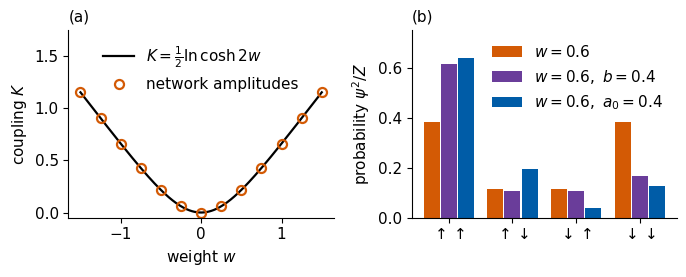

In [5]:
SIG2 = spins(bit_table(2))                                  # the four configurations of two spins: up up, up down, down up, down down

def pair_amplitudes(w, b=0.0, a0=0.0):
    # one hidden unit (M = 1) connected to spins 0 and 1 with weight w, hidden bias b, visible bias a0 on spin 0
    return rbm_amplitude(np.array([a0, 0.0]), np.array([b]), np.array([[w], [w]]), SIG2)   # shape (4,)

w_list = np.linspace(-1.5, 1.5, 13)
K_network = np.array([0.5 * np.log(pair_amplitudes(w)[0] / pair_amplitudes(w)[1]) for w in w_list])   # psi(up up)/psi(up down) = e^{2K}
K_formula = 0.5 * np.log(np.cosh(2 * w_list))                                                         # equation (13)
assert np.allclose(K_network, K_formula)
SETTINGS = {"$w=0.6$": dict(w=0.6), "$w=0.6,\\ b=0.4$": dict(w=0.6, b=0.4), "$w=0.6,\\ a_0=0.4$": dict(w=0.6, a0=0.4)}
print("probabilities psi^2 / Z of      up up   up down   down up   down down")
PAIR_P = {}
for label, kw in SETTINGS.items():
    psi2 = pair_amplitudes(**kw) ** 2
    PAIR_P[label] = psi2 / psi2.sum()
    print(f"  {label.replace('$', '').replace(chr(92) + ' ', ' '):22s}      " + "    ".join(f"{x:.3f}" for x in PAIR_P[label]))
print(f"effective coupling K at w = 0.6: {0.5 * np.log(np.cosh(1.2)):.3f}")

# --- figure (drawing code may be skipped) ---
def draw_unit_a(ax):
    w_fine = np.linspace(-1.5, 1.5, 200)
    ax.plot(w_fine, 0.5 * np.log(np.cosh(2 * w_fine)), color=COL["exact"], lw=1.6, label=r"$K=\frac{1}{2}\ln\cosh 2w$")
    ax.plot(w_list, K_network, "o", color=COL["rbm"], ms=6.5, mfc="none", mew=1.6, label="network amplitudes")
    ax.set_ylim(-0.05, 1.75); ax.set_xlabel("weight $w$"); ax.set_ylabel("coupling $K$"); ax.legend(frameon=False, loc="upper center", fontsize=11)
def draw_unit_b(ax):
    x = np.arange(4)
    for n_, (label, prob) in enumerate(PAIR_P.items()):
        ax.bar(x + (n_ - 1) * 0.27, prob, width=0.25, color=[COL["rbm"], COL["sampled"], COL["blue"]][n_], label=label)
    ax.set_xticks(x); ax.set_xticklabels([r"$\uparrow\uparrow$", r"$\uparrow\downarrow$", r"$\downarrow\uparrow$", r"$\downarrow\downarrow$"])
    ax.set_ylabel(r"probability $\psi^2/Z$"); ax.set_ylim(0, 0.75); ax.legend(frameon=False, fontsize=11, loc="upper right")
panels("fig_lab080_hidden_unit", [draw_unit_a, draw_unit_b])

Panel (a) shows the coupling $K$ read off from the network amplitudes against the weight $w$, on the curve of equation (13). The coupling is even in $w$ and grows linearly for large $|w|$. Panel (b) shows the four probabilities of the two-spin network. With $w=0.6$ alone the two parallel configurations are equally likely and more likely than the antiparallel ones. The hidden bias $b=0.4$ favours the configuration with both spins up over the one with both spins down, and the visible bias $a_0=0.4$ favours spin 0 up whatever spin 1 does.

A hidden unit connected to more than two spins adds couplings beyond pairs, as the case of four spins shows. We connect one hidden unit with zero bias and the same weight $w$ to spins 0 to 3, so that its input is $u=w(\sigma_0+\sigma_1+\sigma_2+\sigma_3)$, and expand the logarithm of its factor for small $u$,
$$\ln\big(2\cosh u\big)=\ln2+\frac{u^2}{2}-\frac{u^4}{12}+\dots \tag{13a}$$
Because $\sigma_i^2=1$, the square contains only pairs of different spins,
$$u^2=w^2\Big(\underbrace{\sigma_0^2+\sigma_1^2+\sigma_2^2+\sigma_3^2}_{=4}+2\sum_{i<k}\sigma_i\sigma_k\Big) , \tag{13b}$$
so the term $u^2/2$ is a coupling $w^2\sigma_i\sigma_k$ between each of the six pairs. The fourth power, multiplied out as a product of four sums, contains the product of the four different spins in $4!=24$ orderings, and the term $-u^4/12$ therefore contains $-2w^4\sigma_0\sigma_1\sigma_2\sigma_3$, a coupling of four spins. The other terms of the fourth power repeat a spin, reduce to pairs and constants by $\sigma_i^2=1$, and correct the pair coupling.

The factor can also be written exactly, without the expansion, as
$$\ln\big(2\cosh u\big)=C+K\sum_{i<k}\sigma_i\sigma_k+K_4\,\sigma_0\sigma_1\sigma_2\sigma_3 . \tag{13c}$$
The left side depends only on how many of the four spins point down and is unchanged when all four are flipped, so three classes of configurations fix the three constants $C$, $K$ and $K_4$. Four parallel spins have the pair sum 6 and the product $+1$. One flipped spin leaves three parallel and three antiparallel pairs, hence the pair sum 0, and gives the product $-1$. Two flipped spins give the pair sum $-2$ and the product $+1$. Equation (13c) then reads
$$\ln(2\cosh4w)=C+6K+K_4,\qquad \ln(2\cosh2w)=C-K_4,\qquad \ln2=C-2K+K_4 . \tag{13d}$$
The first equation minus the last gives $8K=\ln\cosh4w$, and the last equation minus the middle one gives $2K_4-2K=-\ln\cosh2w$, so
$$K=\tfrac18\ln\cosh4w,\qquad K_4=\tfrac18\ln\cosh4w-\tfrac12\ln\cosh2w . \tag{13e}$$
At $w=0.5$ we have $\cosh2=3.762$ and $\cosh1=1.543$, so $K=\tfrac18\cdot1.325=0.166$ and $K_4=0.166-\tfrac12\cdot0.434=-0.051$. For small $w$ the two formulas start as $K\approx w^2$ and $K_4\approx-2w^4$, the coefficients found in the expansion. With a hidden bias the expansion also contains odd powers of $\sigma_0+\sigma_1+\sigma_2+\sigma_3$, and with them fields on single spins and couplings of three spins. A Boltzmann weight with pair couplings alone has no such terms, whereas every hidden unit adds an interaction among all the spins it is connected to.

We fit equation (13c) to the logarithms of the 16 amplitudes of a network with one hidden unit on four spins, print the three classes of configurations at $w=0.5$, and compare the fitted $K$ and $K_4$ with equation (13e) for a range of weights.

w = 0.5, the three classes of configurations of equation (13d):
  four parallel  0000:  pair sum +6,  product +1,  ln psi = ln(2 cosh u) = 2.0181
  one flipped    0001:  pair sum +0,  product -1,  ln psi = ln(2 cosh u) = 1.1269
  two flipped    0011:  pair sum -2,  product +1,  ln psi = ln(2 cosh u) = 0.6931
fit of equation (13c): C = 1.0757, K = 0.1656, K_4 = -0.0513;  largest residual over the 16 configurations 9e-16
equation (13e): K = ln(cosh 2)/8 = 0.1656,  K_4 = K - ln(cosh 1)/2 = -0.0513;  leading terms w^2 = 0.250, -2 w^4 = -0.125


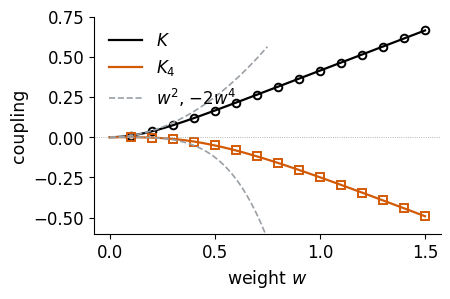

In [6]:
SIG4 = spins(bit_table(4))                                   # the 16 configurations of four spins, shape (16, 4)
PAIRS4 = sum(SIG4[:, i] * SIG4[:, k] for i in range(4) for k in range(i + 1, 4))    # pair sum sum_{i<k} sigma_i sigma_k
BASIS4 = np.column_stack([np.ones(16), PAIRS4, np.prod(SIG4, axis=1)])             # columns of (13c): 1, pair sum, product

def four_spin_couplings(w):
    # ln psi(s) of one hidden unit without biases, weight w to all four spins, fitted by C + K (pair sum) + K_4 (product), equation (13c)
    ln_psi4 = np.log(rbm_amplitude(np.zeros(4), np.zeros(1), np.full((4, 1), w), SIG4))
    coef, *_ = np.linalg.lstsq(BASIS4, ln_psi4, rcond=None)                    # (C, K, K_4)
    return coef, float(np.max(np.abs(BASIS4 @ coef - ln_psi4))), ln_psi4

K_pair4 = lambda w: np.log(np.cosh(4 * w)) / 8                                 # equation (13e)
K_quad4 = lambda w: np.log(np.cosh(4 * w)) / 8 - np.log(np.cosh(2 * w)) / 2
coef_half, resid_half, ln_half = four_spin_couplings(0.5)
print("w = 0.5, the three classes of configurations of equation (13d):")
for k, label in ((0, "four parallel  0000"), (1, "one flipped    0001"), (3, "two flipped    0011")):
    print(f"  {label}:  pair sum {BASIS4[k, 1]:+.0f},  product {BASIS4[k, 2]:+.0f},  ln psi = ln(2 cosh u) = {ln_half[k]:.4f}")
print(f"fit of equation (13c): C = {coef_half[0]:.4f}, K = {coef_half[1]:.4f}, K_4 = {coef_half[2]:.4f};  "
      f"largest residual over the 16 configurations {resid_half:.0e}")
print(f"equation (13e): K = ln(cosh 2)/8 = {K_pair4(0.5):.4f},  K_4 = K - ln(cosh 1)/2 = {K_quad4(0.5):.4f};  "
      f"leading terms w^2 = {0.5 ** 2:.3f}, -2 w^4 = {-2 * 0.5 ** 4:.3f}")
assert resid_half < 1e-12 and np.allclose(coef_half[1:], [K_pair4(0.5), K_quad4(0.5)])
w_four = np.linspace(0.1, 1.5, 15)
fits_four = np.array([four_spin_couplings(w)[0] for w in w_four])              # one row (C, K, K_4) per weight
assert np.allclose(fits_four[:, 1], K_pair4(w_four)) and np.allclose(fits_four[:, 2], K_quad4(w_four))

# --- figure (drawing code may be skipped) ---
def draw_four(ax):
    w_fine = np.linspace(0.0, 1.5, 200)
    ax.plot(w_fine, K_pair4(w_fine), color=COL["exact"], lw=1.6, label=r"$K$")
    ax.plot(w_fine, K_quad4(w_fine), color=COL["rbm"], lw=1.6, label=r"$K_4$")
    ax.plot(w_four, fits_four[:, 1], "o", color=COL["exact"], ms=5.5, mfc="none", mew=1.4)
    ax.plot(w_four, fits_four[:, 2], "s", color=COL["rbm"], ms=5.5, mfc="none", mew=1.4)
    w_small = np.linspace(0.0, 0.75, 100)
    ax.plot(w_small, w_small ** 2, color=COL["grey"], lw=1.2, ls="--", label=r"$w^2$, $-2w^4$")
    ax.plot(w_small, -2 * w_small ** 4, color=COL["grey"], lw=1.2, ls="--")
    ax.axhline(0, color=COL["grey"], lw=0.6, ls=":")
    ax.set_ylim(-0.6, 0.75); ax.set_xlabel("weight $w$"); ax.set_ylabel("coupling"); ax.legend(frameon=False, loc="upper left")
one_panel("fig_lab080_four_spin_coupling", draw_four)

The fit reproduces all 16 logarithms to rounding, with the values $K=0.166$ and $K_4=-0.051$ of the calculation above at $w=0.5$. The figure shows $K$ (black) and $K_4$ (orange) against $w$, from the fits (circles and squares) and from equation (13e) (lines), with the leading terms $w^2$ and $-2w^4$ dashed. The pair coupling is positive, as for two spins, and the four-spin coupling is negative. For small weights the four-spin coupling is far weaker than the pair coupling, of order $w^4$ against $w^2$, and for weights near 1.5 the two have comparable size.

## 5. Energy and local energy

The energy of the state of the network is the expectation value of the Hamiltonian (3),
$$\mathcal E(\boldsymbol\theta)=\frac{\langle\psi_{\boldsymbol\theta}|\hat{\mathcal H}|\psi_{\boldsymbol\theta}\rangle}{\langle\psi_{\boldsymbol\theta}|\psi_{\boldsymbol\theta}\rangle} , \tag{14}$$
where $|\psi_{\boldsymbol\theta}\rangle$ is the state (1) with the amplitudes (11) and the parameters $\boldsymbol\theta$. We write $\mathcal E$ for the energy of a quantum state and keep $E(\boldsymbol\sigma,\mathbf h)$ for the energy of the classical network. Here we only evaluate this energy. The denominator is the sum $Z=\sum_{\mathbf s}\psi(\mathbf s)^2$ of equation (7) over all $2^N$ configurations, and the numerator is a sum of the same length. The partition function of the energy-based models and of the classical Ising model posed the same obstacle, a sum over exponentially many configurations. We print the number of configurations and the memory needed to store one number for each of them.

In [7]:
print("   N   configurations 2^N   memory for one double per configuration")
for n in (12, 50, 100):
    print(f"  {n:3d}   {2.0 ** n:18.3e}   {8 * 2.0 ** n:10.2e} bytes")
NUMBERS.update(ConfigsFifty=sci(2.0 ** 50), ConfigsHundred=sci(2.0 ** 100), MemoryFifty=sci(8 * 2.0 ** 50))

   N   configurations 2^N   memory for one double per configuration
   12            4.096e+03     3.28e+04 bytes
   50            1.126e+15     9.01e+15 bytes
  100            1.268e+30     1.01e+31 bytes


For twelve spins the sums have 4096 terms and take milliseconds. For fifty spins there are about $1.1\times10^{15}$ configurations, and one double-precision number per configuration needs $9.0\times10^{15}$ bytes, about nine petabytes. For a hundred spins the number of configurations, about $1.3\times10^{30}$, exceeds any computer. The exact sums of this notebook do not scale, and for long chains they must be replaced by averages over sampled configurations, which the rest of this section prepares and Section 6 carries out.

To evaluate the energy (14) without the full sums we write the energy as an average over the Born probabilities (7). We insert the identity $\sum_{\mathbf s}|\mathbf s\rangle\langle\mathbf s|$ on both sides of $\hat{\mathcal H}$, use that the amplitudes are real, and multiply and divide each term by $\psi(\mathbf s)$, which is allowed because no amplitude vanishes,
$$\begin{aligned}
\mathcal E(\boldsymbol\theta)&=\frac{\sum_{\mathbf s}\sum_{\mathbf s'}\psi(\mathbf s)\,\langle\mathbf s|\hat{\mathcal H}|\mathbf s'\rangle\,\psi(\mathbf s')}{\sum_{\mathbf s''}\psi(\mathbf s'')^2}
=\sum_{\mathbf s}\frac{\psi(\mathbf s)^2}{\sum_{\mathbf s''}\psi(\mathbf s'')^2}\;\sum_{\mathbf s'}\langle\mathbf s|\hat{\mathcal H}|\mathbf s'\rangle\,\frac{\psi(\mathbf s')}{\psi(\mathbf s)}\\
&=\sum_{\mathbf s}\underbrace{p(\mathbf s)}_{\text{Born probability (7)}}\;\underbrace{E_{\rm loc}(\mathbf s)}_{\text{local energy}} ,\qquad E_{\rm loc}(\mathbf s)=\sum_{\mathbf s'}\langle\mathbf s|\hat{\mathcal H}|\mathbf s'\rangle\,\frac{\psi(\mathbf s')}{\psi(\mathbf s)} .
\end{aligned}\tag{15}$$
The energy is the average of the local energy $E_{\rm loc}(\mathbf s)$ over the snapshots of the state.

The same steps apply to every Pauli string of equation (4), and they give each string a meaning on a single snapshot. The string $\hat\sigma^z_i\hat\sigma^z_{i+1}$ is diagonal, so only $\mathbf s'=\mathbf s$ contributes and its local value is the number $\sigma_i\sigma_{i+1}=\pm1$, which says whether the two neighbours agree. Its average over snapshots, multiplied by $-J$ and summed over bonds, is the average classical Ising energy. The string $\hat\sigma^x_i$ flips spin $i$ and has no value on a single snapshot. Only $\mathbf s'=\mathbf s^{(i)}$ contributes, and its local value is the ratio $\psi(\mathbf s^{(i)})/\psi(\mathbf s)$, which measures how much amplitude sits one flip away from $\mathbf s$. Large ratios mean that the amplitude is spread over many configurations, so the term $-g\sum_i\hat\sigma^x_i$ rewards superposition. With the matrix elements (5) the local energy of the chain is
$$E_{\rm loc}(\mathbf s)=\underbrace{-J\sum_{i=0}^{N-2}\sigma_i\sigma_{i+1}}_{\text{neighbours agree}}\;\underbrace{-\,g\sum_{i=0}^{N-1}\frac{\psi(\mathbf s^{(i)})}{\psi(\mathbf s)}}_{\text{amplitude one flip away}} . \tag{16}$$
The first term favours ordered snapshots and the second favours a state spread over many snapshots, and the ground state balances the two. Only ratios of amplitudes occur, so the normalisation $Z$ never enters the local energy.

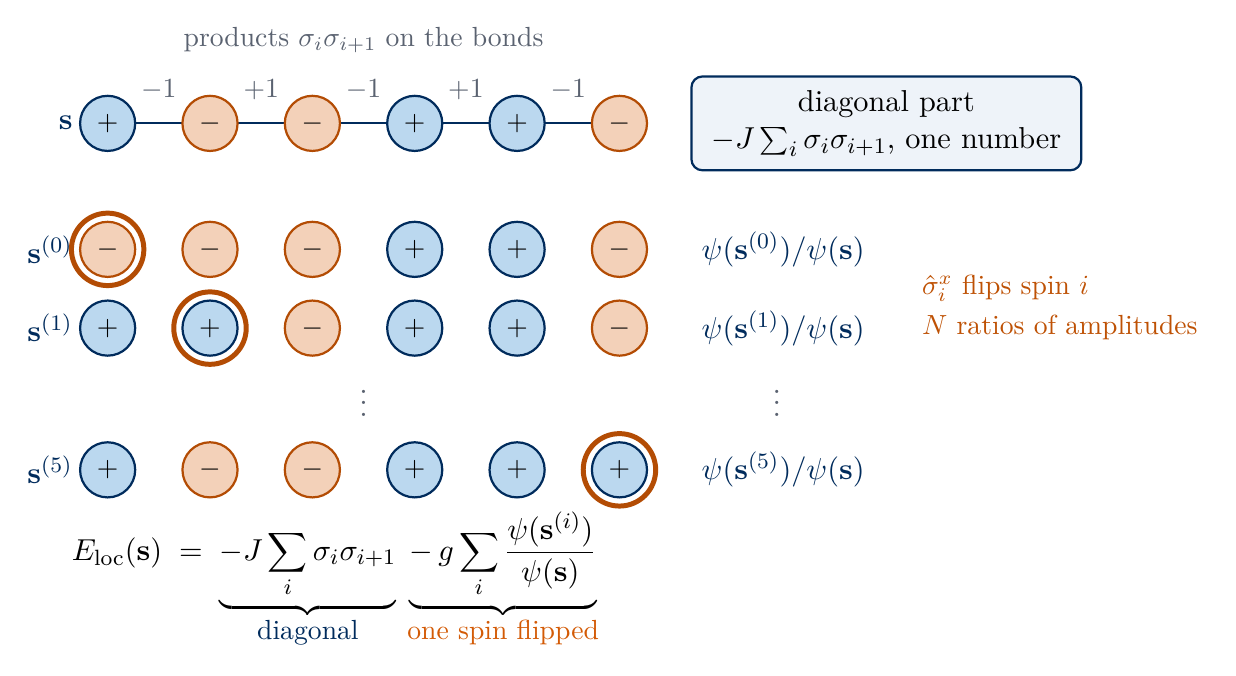

The sketch follows one configuration of six spins. The products $\sigma_i\sigma_{i+1}$ on the bonds give the diagonal part, and each configuration $\mathbf s^{(i)}$, with the circled spin flipped, contributes one ratio of amplitudes.

If $|\psi\rangle$ is an eigenstate of $\hat{\mathcal H}$ with energy $\mathcal E$, then $\sum_{\mathbf s'}\langle\mathbf s|\hat{\mathcal H}|\mathbf s'\rangle\psi(\mathbf s')=\mathcal E\psi(\mathbf s)$ for every $\mathbf s$, and equation (15) gives
$$E_{\rm loc}(\mathbf s)=\mathcal E\quad\text{for every configuration }\mathbf s . \tag{17}$$
At an exact eigenstate every snapshot has the same local energy, and its variance over snapshots vanishes. This zero-variance property makes the local energy fluctuate less the closer the network comes to the ground state.

Two spins show all of this in a few lines. For $N=2$ the Hamiltonian (3) is the $4\times4$ matrix with the diagonal $(-J,+J,+J,-J)$ in the order $00,01,10,11$ and the element $-g$ between configurations that differ in one bit. The symmetry under flipping both spins and under exchanging them suggests the amplitudes $\psi(00)=\psi(11)=\alpha$ and $\psi(01)=\psi(10)=\beta$ with the ratio $\zeta=\beta/\alpha$. Equation (16) gives
$$E_{\rm loc}(00)=-J-g\,\frac{\psi(10)+\psi(01)}{\psi(00)}=-J-2g\zeta,\qquad E_{\rm loc}(01)=+J-g\,\frac{\psi(11)+\psi(00)}{\psi(01)}=J-\frac{2g}{\zeta} , \tag{18}$$
and the same values for $11$ and $10$. By equation (17) the eigenstate has equal local energies. At $g=J$ the condition $-J-2J\zeta=J-2J/\zeta$, multiplied by $\zeta/(2J)$, becomes
$$\zeta^2+\zeta-1=0,\qquad \zeta=\frac{\sqrt5-1}{2} , \tag{19}$$
and both local energies equal $-J-2J\zeta=-\sqrt5\,J$. We compare this value with the lowest eigenvalue of the $4\times4$ matrix and plot the two local energies against $\zeta$. The code writes `r` for the ratio $\zeta$ and `r_star` for its value $(\sqrt5-1)/2$.

matrix of the two-spin chain (rows and columns 00, 01, 10, 11):
 [[-1. -1. -1.  0.]
 [-1.  1.  0. -1.]
 [-1.  0.  1. -1.]
 [ 0. -1. -1. -1.]]
lowest eigenvalue -2.236068 J,  -sqrt(5) J = -2.236068 J
zeta = (sqrt5 - 1)/2 = 0.618034:  E_loc(00) = -2.236068 J,  E_loc(01) = -2.236068 J


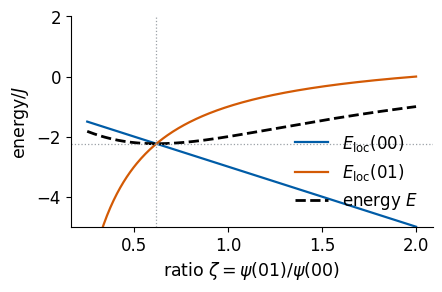

In [8]:
H2 = tfim_matrix(g_c, 2).toarray()                           # the 4 x 4 matrix of the two-spin chain at g = J
E0_two = float(np.linalg.eigvalsh(H2)[0])
r_star = (np.sqrt(5) - 1) / 2                                # equation (19), the ratio zeta of the ground state
e00 = lambda r: -J - 2 * g_c * r                             # equation (18), r is the ratio zeta
e01 = lambda r: J - 2 * g_c / r
print("matrix of the two-spin chain (rows and columns 00, 01, 10, 11):\n", H2)
print(f"lowest eigenvalue {E0_two:.6f} J,  -sqrt(5) J = {-np.sqrt(5):.6f} J")
print(f"zeta = (sqrt5 - 1)/2 = {r_star:.6f}:  E_loc(00) = {e00(r_star):.6f} J,  E_loc(01) = {e01(r_star):.6f} J")
psi_two = np.array([1.0, r_star, r_star, 1.0]); psi_two /= np.linalg.norm(psi_two)
assert np.allclose(H2 @ psi_two, E0_two * psi_two) and abs(E0_two + np.sqrt(5)) < 1e-12

# --- figure (drawing code may be skipped) ---
def draw_two(ax):
    r = np.linspace(0.25, 2.0, 300)
    q = 2 * r ** 2 / (2 + 2 * r ** 2)                          # probability of the two antiparallel configurations
    ax.plot(r, e00(r), color=COL["blue"], lw=1.6, label=r"$E_{\rm loc}(00)$")
    ax.plot(r, e01(r), color=COL["rbm"], lw=1.6, label=r"$E_{\rm loc}(01)$")
    ax.plot(r, (1 - q) * e00(r) + q * e01(r), color=COL["exact"], lw=2.0, ls="--", label=r"energy $E$")
    ax.axvline(r_star, color=COL["grey"], lw=0.9, ls=":")
    ax.axhline(-np.sqrt(5), color=COL["grey"], lw=0.9, ls=":")
    ax.set_ylim(-5, 2); ax.set_xlabel(r"ratio $\zeta=\psi(01)/\psi(00)$"); ax.set_ylabel(r"energy$/J$"); ax.legend(frameon=False, loc="lower right")
one_panel("fig_lab080_two_spins", draw_two)
NUMBERS.update(RStar=f"{r_star:.3f}", EZeroTwo=f"{E0_two:.4f}")

The lowest eigenvalue of the $4\times4$ matrix is $-\sqrt5\,J\approx-2.2361\,J$, and the state with $\zeta=(\sqrt5-1)/2\approx0.618$ is its eigenvector. The figure shows the two local energies (18) and the energy, their average over the Born probabilities, against $\zeta$. The local energies cross at the dotted line $\zeta\approx0.618$, where the energy has its minimum $-\sqrt5\,J$. For any other $\zeta$ the two local energies differ, and the energy lies above the minimum.

For twelve sites we evaluate equations (15) and (16) as exact sums over all 4096 configurations, as a check. The code works with $\ln\psi$, which turns the product (11) into a sum and avoids overflow of the hyperbolic cosine, and it finds $\psi(\mathbf s^{(i)})$ by looking up the index of $\mathbf s^{(i)}$ in a table. We define this energy and check it twice. With all parameters zero every amplitude equals $2^M$, every ratio in (16) equals one, and the energy is $-gN$, because the classical Ising energy averages to zero over all configurations. For random parameters the energy (15) must agree with $\psi^{\mathsf T}H\psi$ computed with the sparse matrix of Section 3.

In [9]:
S = jnp.asarray(SIGMA, dtype=jnp.float64)        # all spin configurations, shape (4096, 12)
FLIP_J, DIAG_J = jnp.asarray(FLIP), jnp.asarray(DIAG)

def log_amplitude(p, sigma):
    # logarithm of equation (11) for real parameters p = dict(a, b, W), p["W"] holds the weights w_ij; sigma has shape (n, N), result shape (n,)
    # ln(2 cosh u) = logaddexp(u, -u) is evaluated without overflow even for large |u|
    u = p["b"] + sigma @ p["W"]                              # shape (n, M)
    return sigma @ p["a"] + jnp.sum(jnp.logaddexp(u, -u), axis=-1)

def local_energies(p, g):
    # equation (16) for all 4096 configurations at once. ln_psi[FLIP] has shape (4096, 12):
    # entry (k, i) is ln psi of configuration k with spin i flipped, so the ratio is exp(difference)
    ln_psi = log_amplitude(p, S)                             # shape (4096,)
    ratios = jnp.exp(ln_psi[FLIP_J] - ln_psi[:, None])       # psi(s^(i)) / psi(s), shape (4096, 12)
    return DIAG_J - g * jnp.sum(ratios, axis=1), ln_psi

def energy(p, g):
    # equation (15) as an exact sum: E(theta) = sum_s p(s) E_loc(s) with p(s) = psi(s)^2 / Z
    e_loc, ln_psi = local_energies(p, g)
    w = jnp.exp(2 * (ln_psi - jnp.max(ln_psi)))              # psi^2 up to a constant factor, no overflow
    return jnp.sum(w * e_loc) / jnp.sum(w)

def rbm_state(p):
    # the 4096 amplitudes of equation (11), normalised to one
    ln_psi = log_amplitude(p, S)
    psi = jnp.exp(ln_psi - jnp.max(ln_psi))
    return psi / jnp.linalg.norm(psi)

def init_params(rng_key, M, width=0.05):
    # small random real parameters: a shape (N,), b shape (M,), weights W shape (N, M)
    k_a, k_b, k_W = jax.random.split(rng_key, 3)
    return dict(a=width * jax.random.normal(k_a, (N,)), b=width * jax.random.normal(k_b, (M,)),
                W=width * jax.random.normal(k_W, (N, M)))

# check 1: all parameters zero give psi(s) = 2^M for every s, so E_loc(s) = DIAG(s) - g N and the energy is -g N
p_zero = dict(a=jnp.zeros(N), b=jnp.zeros(3), W=jnp.zeros((N, 3)))
E_zero = float(energy(p_zero, g_c))
print(f"all parameters zero (equal amplitudes): energy {E_zero:.6f} J, expected -g N = {-g_c * N:.1f} J")
assert abs(E_zero + g_c * N) < 1e-12

# check 2: random parameters, energy (15) from local energies against psi^T H psi with the sparse matrix
p_test = init_params(jax.random.PRNGKey(1), 5, width=0.3)
psi_test = np.asarray(rbm_state(p_test))
E_matrix = float(psi_test @ (ex["H"] @ psi_test))
E_local = float(energy(p_test, g_c))
print(f"random parameters, M = 5: energy from local energies {E_local:.10f} J, from the matrix {E_matrix:.10f} J")
assert abs(E_local - E_matrix) < 1e-10 and E_local > ex["E0"]
NUMBERS.update(EnergyUniform=f"{E_zero:.0f}")

all parameters zero (equal amplitudes): energy -12.000000 J, expected -g N = -12.0 J
random parameters, M = 5: energy from local energies -8.3936396572 J, from the matrix -8.3936396572 J


Both checks pass. The state with equal amplitudes has the energy $-12\,J=-gN$, and for random parameters the two ways of computing the energy agree to numerical precision.

## 6. Sampling the state

To sample a probability distribution $p(\mathbf s)$ means to produce a list of configurations in which every configuration appears with a frequency proportional to $p(\mathbf s)$, as the throws of a loaded die list its faces. For a few configurations this can be done with a table. We take the ground state of the two-spin chain of Section 5, with the amplitudes $\psi(00)=\psi(11)=1$ and $\psi(01)=\psi(10)=\zeta$, $\zeta=(\sqrt5-1)/2$. The norm is $Z=2+2\zeta^2$, so the Born probabilities are $p(00)=p(11)=1/\big(2(1+\zeta^2)\big)$ and $p(01)=p(10)=\zeta^2/\big(2(1+\zeta^2)\big)$. The table lists the four configurations with their probabilities and the cumulative sum of the probabilities down to each row. A random number $\xi$ drawn uniformly between 0 and 1 picks the first row whose cumulative value exceeds $\xi$. The letter $u$ is kept for the input $u_j$ of a hidden unit, and the code writes `xi` for $\xi$. Row $\mathbf s$ covers an interval of length $p(\mathbf s)$, so it is picked with the probability $p(\mathbf s)$. We build the table, draw the configurations for $\xi=0.45$ and $\xi=0.81$, and repeat the draw 4000 times.

In [10]:
# sampling from a table: the two-spin ground state psi = (1, zeta, zeta, 1) for the configurations 00, 01, 10, 11
psi_demo = np.array([1.0, r_star, r_star, 1.0])               # amplitudes, zeta = r_star = (sqrt5 - 1)/2 from Section 5
p_demo = psi_demo ** 2 / np.sum(psi_demo ** 2)                 # Born probabilities psi^2 / Z with Z = 2 + 2 zeta^2
cum_demo = np.cumsum(p_demo)                                   # cumulative column: p(00), p(00) + p(01), ...
labels_demo = ["00", "01", "10", "11"]
rng_demo = np.random.default_rng(8081)                         # own generator, so the other results of the notebook are unchanged

def draw_from_table(xi):
    # index of the first row whose cumulative value exceeds xi (xi uniform in [0, 1))
    return int(np.searchsorted(cum_demo, xi, side="right"))

def table_demo(n_draws):
    print("config   p(s)    cumulative")
    for lab, p_, c_ in zip(labels_demo, p_demo, cum_demo):
        print(f"  {lab}    {p_:.3f}    {c_:.3f}")
    for xi in (0.45, 0.81):
        print(f"xi = {xi:.2f} -> {labels_demo[draw_from_table(xi)]}")
    draws = np.array([draw_from_table(xi) for xi in rng_demo.random(n_draws)])
    freq = np.bincount(draws, minlength=4) / n_draws
    print(f"frequencies of {n_draws} draws: " + "  ".join(f"{labels_demo[k]} {freq[k]:.3f}" for k in range(4)))

table_demo(4000)
NUMBERS.update(DemoPAligned=f"{p_demo[0]:.3f}", DemoPAnti=f"{p_demo[1]:.3f}",
               DemoCumTwo=f"{cum_demo[1]:.3f}", DemoCumThree=f"{cum_demo[2]:.3f}")


config   p(s)    cumulative
  00    0.362    0.362
  01    0.138    0.500
  10    0.138    0.638
  11    0.362    1.000
xi = 0.45 -> 01
xi = 0.81 -> 11
frequencies of 4000 draws: 00 0.366  01 0.139  10 0.134  11 0.361


The frequencies of the draws approach the probabilities of the table. The table needs every probability, and therefore the norm $Z$. For twelve spins it has 4096 rows, and for fifty spins it cannot be stored (Section 5).

The Born probabilities (7) contain the normalisation $Z$, a sum over $2^N$ configurations. The Metropolis algorithm [4], used earlier in the course for the Monte Carlo simulation of the classical Ising model, samples from $p(\mathbf s)$ without ever computing $Z$. A Markov chain sits at a configuration $\mathbf s$, picks a random site $i$, proposes the configuration $\mathbf s'=\mathbf s^{(i)}$ and accepts it with the probability
$$A(\mathbf s\to\mathbf s')=\min\Big(1,\frac{p(\mathbf s')}{p(\mathbf s)}\Big)=\min\Big(1,\frac{\psi(\mathbf s')^2/Z}{\psi(\mathbf s)^2/Z}\Big)=\min\Big(1,\frac{\psi(\mathbf s')^2}{\psi(\mathbf s)^2}\Big) . \tag{20}$$
The normalisation cancels in the ratio, so each proposal needs two amplitudes and nothing else. If the proposal is rejected, the chain stays at $\mathbf s$. The proposal of a random site is symmetric, and the rule (20) then satisfies detailed balance, $p(\mathbf s)A(\mathbf s\to\mathbf s')=p(\mathbf s')A(\mathbf s'\to\mathbf s)$, so that after many steps the chain visits configurations with the probabilities $p(\mathbf s)$. The hidden units never appear, because the amplitude (11) already contains their sum in the closed form of one hyperbolic cosine per hidden unit. The chain moves only through the visible spins, and no hidden configuration is ever sampled.

On the two spins the walk can be followed proposal by proposal. The chain starts at $00$ and proposes to flip one of the two spins, for example to $01$. The ratio $\psi(01)^2/\psi(00)^2=\zeta^2\approx0.382$ is the acceptance probability, so a uniform random number $\xi<\zeta^2$ moves the chain to $01$, and otherwise it stays at $00$ and $00$ is counted again. From $01$ every proposal, to $00$ or to $11$, has the ratio $1/\zeta^2>1$ and is accepted. We run 4000 proposals, record the configuration after every second proposal, one sweep of the two spins, which gives 2000 recorded configurations, and compare the frequencies of the recorded configurations with the probabilities of the table. Only ratios of amplitudes enter, and $Z$ never appears.

In [11]:
# Metropolis walk on the four configurations of two spins, rule (20): accept s -> s' if xi < psi(s')^2 / psi(s)^2
def walk_demo(n_proposals, record_every):
    s = np.array([0, 0])                                       # start at 00
    amp = lambda x: psi_demo[2 * x[0] + x[1]]                  # amplitude of the bit string (s_0, s_1)
    visits = np.zeros(4)
    for t in range(n_proposals):
        site = rng_demo.integers(2)                            # the spin to flip
        s_new = s.copy(); s_new[site] = 1 - s_new[site]
        ratio = amp(s_new) ** 2 / amp(s) ** 2                  # Z cancels: only the ratio of two amplitudes
        xi = rng_demo.random()                                 # the uniform random number xi
        if t < 6:
            print(f"  proposal {t + 1}: at {s[0]}{s[1]}, propose {s_new[0]}{s_new[1]}, ratio {ratio:.3f}, xi = {xi:.3f} -> "
                  + ("accept" if xi < ratio else "stay, count the old configuration again"))
        if xi < ratio:
            s = s_new
        if (t + 1) % record_every == 0:
            visits[2 * s[0] + s[1]] += 1                       # record the current configuration
    return visits

DEMO_PROPOSALS, DEMO_EVERY = 4000, 2                           # record after every 2 proposals, one sweep of N = 2 spins
visits_demo = walk_demo(DEMO_PROPOSALS, DEMO_EVERY)
freq_walk = visits_demo / visits_demo.sum()
print(f"{int(visits_demo.sum())} recorded configurations")
print("config  frequency  p(s)")
for k_ in range(4):
    print(f"  {labels_demo[k_]}     {freq_walk[k_]:.3f}    {p_demo[k_]:.3f}")
NUMBERS.update(DemoRSq=f"{r_star ** 2:.3f}", DemoProposals=f"{DEMO_PROPOSALS}", DemoRecorded=f"{int(visits_demo.sum())}",
               DemoWalkAligned=f"{(freq_walk[0] + freq_walk[3]) / 2:.3f}", DemoWalkAnti=f"{(freq_walk[1] + freq_walk[2]) / 2:.3f}")


  proposal 1: at 00, propose 10, ratio 0.382, xi = 0.148 -> accept
  proposal 2: at 10, propose 00, ratio 2.618, xi = 0.142 -> accept
  proposal 3: at 00, propose 10, ratio 0.382, xi = 0.987 -> stay, count the old configuration again
  proposal 4: at 00, propose 10, ratio 0.382, xi = 0.671 -> stay, count the old configuration again
  proposal 5: at 00, propose 10, ratio 0.382, xi = 0.971 -> stay, count the old configuration again
  proposal 6: at 00, propose 01, ratio 0.382, xi = 0.059 -> accept
2000 recorded configurations
config  frequency  p(s)
  00     0.360    0.362
  01     0.131    0.138
  10     0.139    0.138
  11     0.370    0.362


The walk spends most of its time on the aligned configurations, and the recorded frequencies approach the probabilities of the table, although the walk never computed $Z$. The list of recorded configurations turns every average over $p(\mathbf s)$ into a plain mean over the list.

The classical RBM was sampled differently, by block Gibbs sampling that alternates between drawing all hidden units given the visible ones and all visible units given the hidden ones. That scheme works because the model distribution $P(\mathbf v)=\sum_{\mathbf h}e^{-E(\mathbf v,\mathbf h)}/Z$ is the marginal of the joint Boltzmann distribution of visible and hidden units. The Born rule asks for the square of the amplitude,
$$\psi(\mathbf s)^2=\sum_{\mathbf h}\sum_{\mathbf h'}e^{-E(\boldsymbol\sigma,\mathbf h)-E(\boldsymbol\sigma,\mathbf h')} , \tag{21}$$
which is a marginal of a different joint distribution with two copies $\mathbf h$ and $\mathbf h'$ of the hidden layer. The Metropolis rule (20) works directly with $\psi^2$ and needs neither copy.

Every sampled configuration is a simulated snapshot, the bit string that a measurement of all spins along $z$ would return with the probability $p(\mathbf s)$ of the Born rule. A diagonal observable $\hat O$, a function $O(\mathbf s)$ of the snapshot such as $\sigma_0\sigma_r$ or the total spin $m=\sum_i\sigma_i$, is estimated by the average over $N_{\rm s}$ snapshots,
$$\bar O=\frac{1}{N_{\rm s}}\sum_{n=1}^{N_{\rm s}}O(\mathbf s_n),\qquad \Delta\bar O=\frac{s_O}{\sqrt{N_{\rm s}}} , \tag{22}$$
where $s_O$ is the standard deviation of $O$ over the snapshots (the letter $\sigma$ is kept for spins). The error formula assumes independent snapshots. Successive configurations of one Markov chain are correlated, because a step changes at most one spin. We run 100 chains side by side, discard the first 500 sweeps of $N$ proposals each, and record the configuration after each of the next 2048 sweeps. To obtain reliable errors we group the 2048 recorded values of each chain into consecutive bins of $L$ sweeps and apply equation (22) to the bin averages. When $L$ exceeds the correlation time of the chain, the bin averages are independent and the error stops growing with $L$. Keeping only every $L$-th configuration, called thinning, removes the correlation as well but discards data.

We sample a network with $M=12$ hidden units, whose $168$ parameters were found by lowering the energy (14), computed as an exact sum over all 4096 configurations, from small random starting values. This training was carried out in advance, outside this notebook, and wrote the trained parameters, together with their starting values, to the file `data/rbm_tfim_N12_M12_params.npz`. We load both sets of parameters, check the trained network against the exact ground state of Section 3 with exact sums, and then run the chains for the trained parameters and for the starting values, and draw a few snapshots.

In [12]:
saved = np.load(DATA / "rbm_tfim_N12_M12_params.npz")                 # trained in advance by exact-sum energy minimisation
p_ref = {k_: jnp.asarray(saved[k_]) for k_ in ("a", "b", "W")}           # trained a_i, b_j and weights w_ij (key "W"), shapes (N,), (M,), (N, M)
p_init = {k_: jnp.asarray(saved[k_ + "_init"]) for k_ in ("a", "b", "W")}   # the same network at its small random starting values
M_MAIN = int(p_ref["b"].shape[0])                                      # number of hidden units, 12
n_params = N + M_MAIN + N * M_MAIN                                     # a_i, b_j and w_ij
psi_loaded = np.asarray(rbm_state(p_ref))                              # the 4096 normalised amplitudes of the trained network
E_loaded = float(psi_loaded @ (ex["H"] @ psi_loaded))
F_loaded = float((psi_loaded @ ex["psi0"]) ** 2)                       # fidelity with the exact ground state
print(f"trained network: M = {M_MAIN} hidden units, {n_params} parameters for {DIM} amplitudes")
print(f"  energy (14) as an exact sum {E_loaded:.6f} J, exact ground state {ex['E0']:.6f} J, "
      f"relative difference {(E_loaded - ex['E0']) / abs(ex['E0']):.1e}, infidelity {1 - F_loaded:.1e}")
print(f"starting values: energy {float(energy(p_init, g_c)):.4f} J, largest |parameter| {max(float(jnp.max(jnp.abs(v))) for v in p_init.values()):.3f}")
NUMBERS.update(HiddenMain=str(M_MAIN), ParamsMain=str(n_params))

trained network: M = 12 hidden units, 168 parameters for 4096 amplitudes
  energy (14) as an exact sum -14.925766 J, exact ground state -14.925971 J, relative difference 1.4e-05, infidelity 2.6e-05
starting values: energy -11.8267 J, largest |parameter| 0.170


In [13]:
FLIP_ONE = jnp.asarray(1 - 2 * np.eye(N))                              # row i multiplies spin i by -1, shape (N, N)

def metropolis_sweeps(p, sigma, rng_key, sweeps):
    # Metropolis rule (20) on the visible spins only; n chains run side by side, sigma (n, N) holds their configurations.
    # One proposal: every chain picks a random site i and proposes s -> s^(i). It is accepted when ln xi < 2 (ln psi(s') - ln psi(s))
    # with xi uniform in (0, 1), which is min(1, psi(s')^2 / psi(s)^2) of equation (20). Z and the hidden units never appear.
    # One sweep = N proposals. Returns the configurations after every sweep, shape (sweeps, n, N), and the acceptance rate.
    n = sigma.shape[0]
    def proposal(carry, k):
        sigma, ln_psi = carry
        k_site, k_acc = jax.random.split(k)
        site = jax.random.randint(k_site, (n,), 0, N)                    # one random site per chain, shape (n,)
        sigma_new = sigma * (1 - 2 * jax.nn.one_hot(site, N))            # flip that spin, shape (n, N)
        ln_new = log_amplitude(p, sigma_new)
        accept = jnp.log(jax.random.uniform(k_acc, (n,))) < 2 * (ln_new - ln_psi)
        return (jnp.where(accept[:, None], sigma_new, sigma), jnp.where(accept, ln_new, ln_psi)), accept
    # jax.lax.scan(f, carry, keys) calls f once per key inside the compiled code and passes carry = (sigma, ln_psi) on
    def sweep(carry, k):
        carry, accepted = jax.lax.scan(proposal, carry, jax.random.split(k, N))
        return carry, (carry[0], jnp.mean(accepted))
    _, (history, acc) = jax.lax.scan(sweep, (sigma, log_amplitude(p, sigma)), jax.random.split(rng_key, sweeps))
    return history, jnp.mean(acc)
sample_sweeps = jax.jit(metropolis_sweeps, static_argnums=3)

CHAINS, BURN, RECORD, L_BIN = 100, 500, 2048, 32
rng_mc = np.random.default_rng(8080)
random_spins = lambda n: jnp.asarray(1 - 2 * rng_mc.integers(0, 2, (n, N)), dtype=jnp.float64)   # random starting configurations
k_ref, k_init = jax.random.split(jax.random.fold_in(key, 1000), 4)[:2]  # keys of the two runs (the other two were used for the training)
t0 = time.perf_counter()
SNAP = {}
for name, p, k in (("trained", p_ref, k_ref), ("initial", p_init, k_init)):
    history, acc = sample_sweeps(p, random_spins(CHAINS), k, BURN + RECORD)
    SNAP[name] = dict(sigma=np.asarray(history[BURN:]), acc=float(acc))   # recorded snapshots, shape (RECORD, CHAINS, N)
    print(f"{name:8s} parameters: {CHAINS} chains, {BURN} + {RECORD} sweeps, acceptance {acc:.2f}")
time_sampling = time.perf_counter() - t0
snaps = SNAP["trained"]["sigma"]
print(f"{RECORD * CHAINS} recorded snapshots of {N} spins for the trained network, shape {snaps.shape}, {time_sampling:.1f} s")
print("first five snapshots of chain 0 (bits s_i):")
for t in range(0, 50, 10):
    print("  ", "".join(str(x) for x in ((1 - snaps[t, 0]) // 2).astype(int)))
NUMBERS.update(SampledChains=str(CHAINS), SampledBurn=str(BURN), SampledSweeps=str(RECORD), BinLength=str(L_BIN),
               SampledSnapshots=str(RECORD * CHAINS), AcceptTrained=f"{SNAP['trained']['acc']:.2f}")

trained  parameters: 100 chains, 500 + 2048 sweeps, acceptance 0.38
initial  parameters: 100 chains, 500 + 2048 sweeps, acceptance 0.88
204800 recorded snapshots of 12 spins for the trained network, shape (2048, 100, 12), 3.3 s
first five snapshots of chain 0 (bits s_i):
   111111011111
   001111111110
   111000111110
   111111111111
   000000000000


The trained network accepts about 0.38 of the proposals. The printed snapshots are configurations of chain 0 ten sweeps apart. They contain long domains of aligned spins, as expected from the positive correlation function of Section 3.

For a diagonal observable the sample average (22) is all we need. For an off-diagonal Pauli string the same insertion of the identity as in equation (15) gives the expectation value as an average of a local value over the snapshots,
$$\langle\hat O\rangle=\sum_{\mathbf s}p(\mathbf s)\,O_{\rm loc}(\mathbf s),\qquad O_{\rm loc}(\mathbf s)=\sum_{\mathbf s'}\langle\mathbf s|\hat O|\mathbf s'\rangle\frac{\psi(\mathbf s')}{\psi(\mathbf s)} . \tag{23}$$
A Pauli string has exactly one nonzero element in every row, so the sum over $\mathbf s'$ has one term. Each $\hat\sigma^x_i$ or $\hat\sigma^y_i$ in the string flips spin $i$, each $\hat\sigma^z_i$ multiplies by $\sigma_i$, and each $\hat\sigma^y_i$ also multiplies by $-i\sigma_i$, where $\sigma_i$ is taken in $\mathbf s$ before the flip. The last rule follows from the matrix $\hat\sigma^y=\begin{pmatrix}0&-i\\ i&0\end{pmatrix}$ in the basis $(|0\rangle,|1\rangle)$, whose elements $\langle0|\hat\sigma^y|1\rangle=-i$ and $\langle1|\hat\sigma^y|0\rangle=+i$ equal $-i\sigma_i$ with $\sigma_i=+1$ for the bit 0 and $\sigma_i=-1$ for the bit 1. With $\mathbf s^{(ij)}$ the configuration with spins $i$ and $j$ flipped, the strings used here have the local values

| string | local value $O_{\rm loc}(\mathbf s)$ |
|---|---|
| $\hat\sigma^z_i$ | $\sigma_i$ |
| $\hat\sigma^z_i\hat\sigma^z_j$ | $\sigma_i\sigma_j$ |
| $\hat\sigma^x_i$ | $\psi(\mathbf s^{(i)})/\psi(\mathbf s)$ |
| $\hat\sigma^y_i$ | $-i\sigma_i\,\psi(\mathbf s^{(i)})/\psi(\mathbf s)$ |
| $\hat\sigma^x_i\hat\sigma^x_j$ | $\psi(\mathbf s^{(ij)})/\psi(\mathbf s)$ |
| $\hat\sigma^y_i\hat\sigma^y_j$ | $-\sigma_i\sigma_j\,\psi(\mathbf s^{(ij)})/\psi(\mathbf s)$ |

For a real positive wave function the expectation value of $\hat\sigma^y_i$ vanishes. The configurations $\mathbf s$ and $\mathbf s^{(i)}$ enter the sum (23) with the same product $\psi(\mathbf s)\psi(\mathbf s^{(i)})$ and opposite signs of $\sigma_i$, so they cancel in pairs. A single snapshot still has a nonzero, purely imaginary local value. A state with a nonzero $\langle\hat\sigma^y_i\rangle$ needs complex amplitudes and therefore complex parameters of the network. In an experiment the strings with $\hat\sigma^x$ and $\hat\sigma^y$ require measurements in rotated bases, whereas with a neural quantum state the $z$ snapshots together with the amplitude ratios give every string.

We implement this rule for any string, check the sign convention against the $2\times2$ matrix of $\hat\sigma^y$, and compare the sampled averages over the snapshots of the trained network with the exact expectation values $\langle\psi|\hat O|\psi\rangle$ computed from Kronecker products of Pauli matrices and the 4096 normalised amplitudes. The errors come from bins of 32 sweeps.

In [14]:
def pauli_local(p, sigma, string):
    # local value (23) of a Pauli string on every snapshot; string = {site: "X" | "Y" | "Z"}, sigma shape (n, N)
    # X or Y flips the spin, Z multiplies by sigma_i, Y also multiplies by -1j * sigma_i (sigma_i before the flip)
    factor = np.ones(sigma.shape[0], dtype=complex)
    flip = np.ones(N)
    for i, op in string.items():
        if op == "Z":
            factor = factor * sigma[:, i]
        if op == "Y":
            factor = factor * (-1j) * sigma[:, i]
        if op in "XY":
            flip[i] = -1.0
    if np.all(flip == 1):
        return factor
    ratio = np.exp(np.asarray(log_amplitude(p, jnp.asarray(sigma * flip))) - np.asarray(log_amplitude(p, jnp.asarray(sigma))))
    return factor * ratio                                                # psi(s') / psi(s) times the phase

# check (may be skipped): the rule for Y against the 2 x 2 matrix, basis (|0>, |1>), sigma = +1 for bit 0 and -1 for bit 1
Y2 = np.array([[0, -1j], [1j, 0]])
assert Y2[0, 1] == -1j * (+1) and Y2[1, 0] == -1j * (-1)               # <s|Y|s^(i)> = -i sigma_i with sigma_i taken in s

PAULI = dict(I=sparse.identity(2, format="csr"), X=sparse.csr_matrix([[0, 1], [1, 0]]), Y=sparse.csr_matrix(Y2),
             Z=sparse.csr_matrix([[1, 0], [0, -1]]))
def pauli_matrix(string):
    # the 2^N x 2^N sparse matrix of a Pauli string, qubit 0 leftmost; independent of the rule in pauli_local
    out = sparse.identity(1, format="csr")
    for q in range(N):
        out = sparse.kron(out, PAULI[string.get(q, "I")], format="csr")
    return out

def binned(x, L):
    # mean and error (22) of a recorded series x with shape (RECORD, CHAINS) from bins of L consecutive sweeps per chain
    bins = x.reshape(x.shape[0] // L, L, x.shape[1]).mean(axis=1)       # shape (RECORD // L, CHAINS)
    return float(x.mean()), float(bins.std(ddof=1) / np.sqrt(bins.size))

flat = snaps.reshape(-1, N)                                             # all recorded snapshots, shape (RECORD * CHAINS, N)
psi_ref = np.asarray(rbm_state(p_ref))                                  # the 4096 exact normalised amplitudes of the same network
i0 = N // 2 - 1                                                         # the strings act on the middle of the chain, sites 5 and 6
STRINGS = {"Z_5 Z_6": {i0: "Z", i0 + 1: "Z"}, "X_5": {i0: "X"}, "Y_5": {i0: "Y"},
           "X_5 X_6": {i0: "X", i0 + 1: "X"}, "Y_5 Y_6": {i0: "Y", i0 + 1: "Y"}}
PAULI_CHECK = {}
print("  string     sampled (real part)       sampled (imaginary part)   exact <psi|O|psi>     deviation / error")
for name, string in STRINGS.items():
    values = pauli_local(p_ref, flat, string).reshape(RECORD, CHAINS)
    re_mean, re_err = binned(values.real, L_BIN)
    im_mean, im_err = binned(values.imag, L_BIN)
    exact_value = complex(psi_ref @ (pauli_matrix(string) @ psi_ref))
    dev = abs(re_mean - exact_value.real) / re_err if re_err > 0 else 0.0
    PAULI_CHECK[name] = dict(mean=re_mean, err=re_err, imag=im_mean, imag_err=im_err, exact=exact_value.real, exact_imag=exact_value.imag)
    print(f"  {name:8s}   {re_mean:+.5f} +- {re_err:.5f}      {im_mean:+.5f} +- {im_err:.5f}         {exact_value.real:+.5f}{exact_value.imag:+.1e}i      {dev:.1f}")
NUMBERS.update(PauliXSampled=f"{PAULI_CHECK['X_5']['mean']:.4f}", PauliXError=f"{PAULI_CHECK['X_5']['err']:.4f}",
               PauliXExact=f"{PAULI_CHECK['X_5']['exact']:.4f}", PauliYImagSampled=f"{PAULI_CHECK['Y_5']['imag']:.4f}",
               PauliYImagError=f"{PAULI_CHECK['Y_5']['imag_err']:.4f}")

  string     sampled (real part)       sampled (imaginary part)   exact <psi|O|psi>     deviation / error
  Z_5 Z_6    +0.59401 +- 0.00221      +0.00000 +- 0.00000         +0.59680+0.0e+00i      1.3
  X_5        +0.67941 +- 0.00209      +0.00000 +- 0.00000         +0.67752+0.0e+00i      0.9
  Y_5        +0.00000 +- 0.00000      +0.00178 +- 0.00285         +0.00000+4.2e-18i      0.0
  X_5 X_6    +0.61382 +- 0.00229      +0.00000 +- 0.00000         +0.61028+0.0e+00i      1.5
  Y_5 Y_6    -0.25589 +- 0.00226      +0.00000 +- 0.00000         -0.25340+0.0e+00i      1.1


All five sampled averages agree with the exact expectation values within at most one and a half statistical errors, the scatter expected from random sampling. The string $\hat\sigma^y_5$ has a zero real part on every snapshot, and its imaginary part averages to zero within the error, as the pairing argument above requires. The two-site strings $\hat\sigma^x_5\hat\sigma^x_6$ and $\hat\sigma^y_5\hat\sigma^y_6$ have different values although both flip the same two spins, because the factor $-\sigma_5\sigma_6$ of $\hat\sigma^y_5\hat\sigma^y_6$ is negative on the many snapshots in which the two neighbours agree.

We evaluate the remaining observables of the chain from the same snapshots. We histogram the total spin $m=\sum_i\sigma_i$, compute the correlation function (8), and split the local energy (16) of every snapshot into its coupling part $-J\sum_i\sigma_i\sigma_{i+1}$ and its field part $-g\sum_i\psi(\mathbf s^{(i)})/\psi(\mathbf s)$. Each sampled value is set beside the exact sum over all 4096 configurations of the same network.

  r    C(r) sampled          C(r) exact     deviation / error
   1   0.5075 +- 0.0022      0.5075         0.0
   2   0.3709 +- 0.0024      0.3727         0.8
   3   0.3012 +- 0.0026      0.3021         0.4
   4   0.2541 +- 0.0027      0.2561         0.7
   5   0.2229 +- 0.0028      0.2227         0.1
   6   0.1943 +- 0.0029      0.1965         0.8
   7   0.1736 +- 0.0029      0.1734         0.1
   8   0.1515 +- 0.0029      0.1528         0.5
   9   0.1279 +- 0.0029      0.1322         1.5
  10   0.1088 +- 0.0029      0.1097         0.3
  11   0.0808 +- 0.0027      0.0800         0.3
largest deviation of P(m) in units of its error: 2.2

energy of the trained network, sampled +- error (bins of 32 sweeps) and exact sum:
  coupling part -J sum s_i s_i+1           -6.26924 +- 0.01038    exact   -6.27352    deviation / error 0.4
  field part -g sum psi(s^(i))/psi(s)      -8.65667 +- 0.01038    exact   -8.65225    deviation / error 0.4
  energy                                  -14.92591 +- 0.

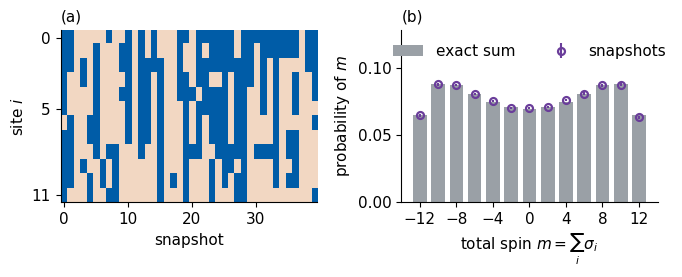

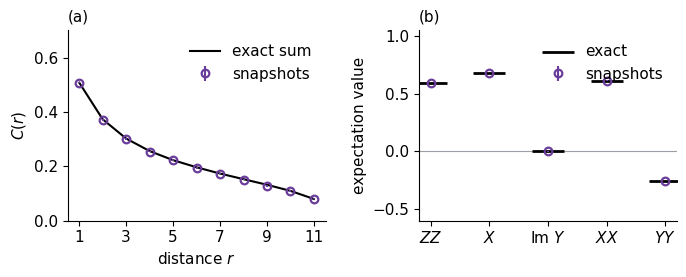

In [15]:
def local_energy_parts(p, sigma, g):
    # equation (16) on snapshots sigma (n, N): coupling part -J sum sigma_i sigma_{i+1} and field part -g sum_i psi(s^(i))/psi(s)
    ln_psi = log_amplitude(p, sigma)                                     # shape (n,)
    # sigma[:, None, :] * FLIP_ONE[None] has shape (n, N, N): copy i of snapshot n has spin i flipped
    ln_flipped = log_amplitude(p, (sigma[:, None, :] * FLIP_ONE[None]).reshape(-1, N)).reshape(-1, N)   # ln psi(s^(i)), shape (n, N)
    e_zz = -J * jnp.sum(sigma[:, :-1] * sigma[:, 1:], axis=-1)
    e_x = -g * jnp.sum(jnp.exp(ln_flipped - ln_psi[:, None]), axis=-1)
    return e_zz, e_x
energy_parts = jax.jit(local_energy_parts)

prob_ref = psi_ref ** 2                                                 # exact Born probabilities of the trained network
M_AXIS = np.arange(-N, N + 1, 2)                                        # possible values of m = sum_i sigma_i
MAG = SIGMA.sum(axis=1)
P_m_exact = np.array([prob_ref[MAG == m].sum() for m in M_AXIS])
m_snap = snaps.sum(axis=-1)                                             # shape (RECORD, CHAINS)
P_m = np.array([binned((m_snap == m).astype(float), L_BIN) for m in M_AXIS])          # columns: mean, error
C_samp = np.array([binned(snaps[..., 0] * snaps[..., r], L_BIN) for r in range(1, N)])
C_exact_ref = correlations(prob_ref)

ENERGY = {}
for name in ("trained", "initial"):
    p_ = p_ref if name == "trained" else p_init
    e_zz, e_x = (np.asarray(x).reshape(RECORD, CHAINS) for x in energy_parts(p_, jnp.asarray(SNAP[name]["sigma"].reshape(-1, N)), g_c))
    psi_ = np.asarray(rbm_state(p_))
    exact_zz = float(DIAG @ psi_ ** 2)                                   # <-J sum Z Z> as an exact sum
    exact_x = float(psi_ @ (ex["H"] @ psi_)) - exact_zz                 # the rest of <H> is the field part
    ENERGY[name] = dict(e_loc=e_zz + e_x, zz=binned(e_zz, L_BIN), x=binned(e_x, L_BIN), total=binned(e_zz + e_x, L_BIN),
                        exact_zz=exact_zz, exact_x=exact_x, exact=exact_zz + exact_x,
                        sigma_loc=float(np.std(e_zz + e_x, ddof=1)))
print("  r    C(r) sampled          C(r) exact     deviation / error")
for r in range(1, N):
    print(f"  {r:2d}   {C_samp[r - 1, 0]:.4f} +- {C_samp[r - 1, 1]:.4f}      {C_exact_ref[r - 1]:.4f}         {abs(C_samp[r - 1, 0] - C_exact_ref[r - 1]) / C_samp[r - 1, 1]:.1f}")
print(f"largest deviation of P(m) in units of its error: {np.max(np.abs(P_m[:, 0] - P_m_exact) / np.maximum(P_m[:, 1], 1e-12)):.1f}")
print("\nenergy of the trained network, sampled +- error (bins of", L_BIN, "sweeps) and exact sum:")
for part, label in (("zz", "coupling part -J sum s_i s_i+1"), ("x", "field part -g sum psi(s^(i))/psi(s)"), ("total", "energy")):
    exact_value = ENERGY["trained"]["exact" if part == "total" else "exact_" + part]
    m_, e_ = ENERGY["trained"][part]
    print(f"  {label:38s} {m_:10.5f} +- {e_:.5f}    exact {exact_value:10.5f}    deviation / error {abs(m_ - exact_value) / e_:.1f}")
print(f"standard deviation of the local energy: initial parameters {ENERGY['initial']['sigma_loc']:.3f} J,"
      f" trained {ENERGY['trained']['sigma_loc']:.4f} J")

# --- figure (drawing code may be skipped) ---
def draw_snap_a(ax):
    picture = snaps[::20, 0, :][:40]                                    # 40 snapshots of chain 0, 20 sweeps apart
    ax.imshow(picture.T, cmap=plt.matplotlib.colors.ListedColormap([COL["blue"], "#F2D7C2"]), aspect="auto", interpolation="nearest")
    ax.set_xlabel("snapshot"); ax.set_ylabel("site $i$"); ax.set_yticks([0, 5, 11])
def draw_snap_b(ax):
    ax.bar(M_AXIS, P_m_exact, width=1.5, color=COL["grey"], label="exact sum")
    ax.errorbar(M_AXIS, P_m[:, 0], yerr=P_m[:, 1], fmt="o", color=COL["sampled"], ms=5, mfc="none", mew=1.6, label="snapshots")
    ax.set_xlabel(r"total spin $m=\sum_i\sigma_i$"); ax.set_ylabel("probability of $m$"); ax.set_xticks(M_AXIS[::2])
    ax.set_ylim(0, 1.45 * P_m_exact.max()); ax.legend(frameon=False, loc="upper center", fontsize=11, ncol=2)
panels("fig_lab080_snapshots", [draw_snap_a, draw_snap_b])
def draw_obs_a(ax):
    ax.plot(range(1, N), C_exact_ref, color=COL["exact"], lw=1.5, label="exact sum")
    ax.errorbar(range(1, N), C_samp[:, 0], yerr=C_samp[:, 1], fmt="o", color=COL["sampled"], ms=5.5, mfc="none", mew=1.6, label="snapshots")
    ax.set_xticks(range(1, N, 2)); ax.set_xlabel("distance $r$"); ax.set_ylabel("$C(r)$"); ax.set_ylim(0, 0.7); ax.legend(frameon=False)
def draw_obs_b(ax):
    names = list(STRINGS)
    x = np.arange(len(names))
    vals = [PAULI_CHECK[n_]["mean"] if n_ != "Y_5" else PAULI_CHECK[n_]["imag"] for n_ in names]
    errs = [PAULI_CHECK[n_]["err"] if n_ != "Y_5" else PAULI_CHECK[n_]["imag_err"] for n_ in names]
    exact_vals = [PAULI_CHECK[n_]["exact"] if n_ != "Y_5" else PAULI_CHECK[n_]["exact_imag"] for n_ in names]
    ax.scatter(x, exact_vals, marker="_", s=500, color=COL["exact"], lw=2, label="exact", zorder=3)
    ax.errorbar(x, vals, yerr=errs, fmt="o", color=COL["sampled"], ms=5.5, mfc="none", mew=1.6, label="snapshots", zorder=4)
    ax.axhline(0, color=COL["grey"], lw=0.8)
    ax.set_xticks(x); ax.set_xticklabels([r"$ZZ$", r"$X$", r"Im $Y$", r"$XX$", r"$YY$"])
    ax.set_ylabel("expectation value"); ax.set_ylim(-0.6, 1.05); ax.legend(frameon=False, fontsize=11, loc="upper right")
panels("fig_lab080_sampled_observables", [draw_obs_a, draw_obs_b])
NUMBERS.update(EnergyZZSampled=f"{ENERGY['trained']['zz'][0]:.3f}", EnergyZZExact=f"{ENERGY['trained']['exact_zz']:.3f}",
               EnergyXSampled=f"{ENERGY['trained']['x'][0]:.3f}", EnergyXExact=f"{ENERGY['trained']['exact_x']:.3f}",
               EstimateTrained=f"{ENERGY['trained']['total'][0]:.5f}", EstimateTrainedError=f"{ENERGY['trained']['total'][1]:.5f}",
               ExactSumTrained=f"{ENERGY['trained']['exact']:.5f}",
               DeviationTrained=f"{abs(ENERGY['trained']['total'][0] - ENERGY['trained']['exact']) / ENERGY['trained']['total'][1]:.1f}",
               EstimateInitial=f"{ENERGY['initial']['total'][0]:.3f}", EstimateInitialError=f"{ENERGY['initial']['total'][1]:.3f}",
               ExactSumInitial=f"{ENERGY['initial']['exact']:.3f}",
               DeviationInitial=f"{abs(ENERGY['initial']['total'][0] - ENERGY['initial']['exact']) / ENERGY['initial']['total'][1]:.1f}",
               SigmaLocInitial=f"{ENERGY['initial']['sigma_loc']:.2f}", ErrPartTrained=f"{ENERGY['trained']['zz'][1]:.3f}", SigmaLocTrained=f"{ENERGY['trained']['sigma_loc']:.3f}")

In the first figure, panel (a) shows 40 snapshots of one chain as columns, with spin up light and spin down blue, and panel (b) the probability of the total spin $m$ from the snapshots (circles with errors) on the exact distribution of the same network (bars). The distribution is symmetric under $m\to-m$ and broad, and each of the two fully aligned configurations at $m=\pm12$ alone carries a sizable probability, a sign of the strong ferromagnetic correlations at the critical field. In the second figure, panel (a) shows the sampled correlation function on the exact curve, and panel (b) the five Pauli strings evaluated above, sampled (circles) and exact (bars), with the imaginary part plotted for $\hat\sigma^y_5$. The figure labels write $X$, $Y$, $Z$ for $\hat\sigma^x_5$, $\hat\sigma^y_5$, $\hat\sigma^z_5$ and $XX$, $YY$, $ZZ$ for the strings on sites 5 and 6.

The energy splits into a coupling part of about $-6.269\,J$ and a field part of about $-8.657\,J$, close to the exact values $-6.274\,J$ and $-8.652\,J$. Each part fluctuates strongly from snapshot to snapshot, and its error is about $0.010\,J$. The fluctuations of the two parts cancel in their sum, the local energy, whose error is about a hundred times smaller, because the trained network is close to an eigenstate. At the critical field the ordering coupling and the spreading field contribute comparable amounts, and the ground state lowers neither term to its own minimum. The full sampled energy is $-14.92591\pm0.00010\,J$ against the exact sum $-14.92577\,J$ of the same network.

To see the zero-variance property (17) and the effect of the correlation between successive sweeps, we histogram the local energy of the snapshots of the trained and of the initial network. For the trained network we then compute the errors of the sampled energy and of the sampled square of the total spin, $m^2$, for bin lengths from one to 512 sweeps.

  bin length L   error of the energy   error of m^2
       1         9.49e-05              1.05e-01
       2         9.51e-05              1.30e-01
       4         9.54e-05              1.56e-01
       8         9.55e-05              1.75e-01
      16         9.61e-05              1.85e-01
      32         9.68e-05              1.91e-01
      64         9.68e-05              1.94e-01
     128         9.66e-05              1.92e-01
     256         9.40e-05              1.89e-01
     512         9.59e-05              1.91e-01
energy: error from bins of 32 sweeps / error for independent snapshots = 1.02
m2: error from bins of 32 sweeps / error for independent snapshots = 1.82
m^2 sampled 55.80 +- 0.19, exact sum 56.10


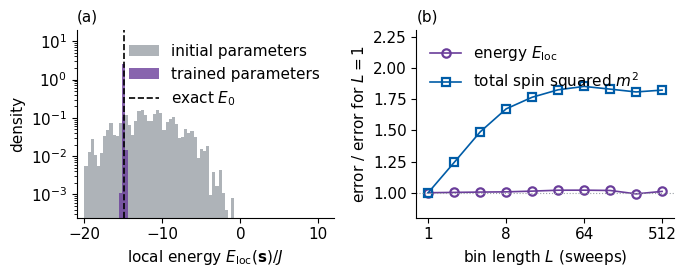

In [16]:
L_LIST = [1, 2, 4, 8, 16, 32, 64, 128, 256, 512]
SERIES = {"energy": ENERGY["trained"]["e_loc"], "m2": m_snap.astype(float) ** 2}     # two observables of the trained network
BIN_ERR = {name: [binned(x, L)[1] for L in L_LIST] for name, x in SERIES.items()}
print("  bin length L   error of the energy   error of m^2")
for L, a_, b_ in zip(L_LIST, BIN_ERR["energy"], BIN_ERR["m2"]):
    print(f"  {L:6d}         {a_:.2e}              {b_:.2e}")
for name in SERIES:
    print(f"{name}: error from bins of {L_BIN} sweeps / error for independent snapshots = {BIN_ERR[name][L_LIST.index(L_BIN)] / BIN_ERR[name][0]:.2f}")
m2_exact = float((MAG.astype(float) ** 2) @ prob_ref)
m2_mean, m2_err = binned(SERIES["m2"], L_BIN)
print(f"m^2 sampled {m2_mean:.2f} +- {m2_err:.2f}, exact sum {m2_exact:.2f}")

# --- figure (drawing code may be skipped) ---
def draw_est_a(ax):
    for name, c in (("initial", COL["grey"]), ("trained", COL["sampled"])):
        ax.hist(ENERGY[name]["e_loc"].ravel(), bins=np.linspace(-20, 4, 61), color=c, alpha=0.8, density=True, label=f"{name} parameters")
    ax.axvline(ex["E0"], color=COL["exact"], ls="--", lw=1.2, label=r"exact $E_0$")
    ax.set_yscale("log"); ax.set_xlabel(r"local energy $E_{\rm loc}(\mathbf{s})/J$"); ax.set_ylabel("density"); ax.set_xlim(-21, 12)
    ax.set_ylim(top=ax.get_ylim()[1] * 5); ax.legend(frameon=False, loc="upper right", fontsize=11)
def draw_est_b(ax):
    for name, c, mk, lab in (("energy", COL["sampled"], "o", r"energy $E_{\rm loc}$"), ("m2", COL["blue"], "s", r"total spin squared $m^2$")):
        ratio = np.array(BIN_ERR[name]) / BIN_ERR[name][0]
        ax.semilogx(L_LIST, ratio, mk + "-", color=c, ms=6, mfc="none", mew=1.6, lw=1.2, label=lab)
    ax.axhline(1, color=COL["grey"], lw=0.8, ls=":")
    ax.set_xticks(L_LIST[::3]); ax.set_xticklabels([str(L) for L in L_LIST[::3]]); ax.minorticks_off()
    ax.set_ylim(0.8, 2.3); ax.set_xlabel("bin length $L$ (sweeps)"); ax.set_ylabel("error / error for $L=1$")
    ax.legend(frameon=False, fontsize=11, loc="upper left")
panels("fig_lab080_sampled_energy", [draw_est_a, draw_est_b])
NUMBERS.update(BinRatioEnergy=f"{BIN_ERR['energy'][L_LIST.index(L_BIN)] / BIN_ERR['energy'][0]:.1f}",
               BinRatioMagSq=f"{BIN_ERR['m2'][L_LIST.index(L_BIN)] / BIN_ERR['m2'][0]:.1f}")

Panel (a) shows the distribution of the local energy on a logarithmic vertical axis. For the initial parameters, close to equal amplitudes, it spreads over many units of $J$, with a standard deviation $s_{\rm loc}=3.34\,J$. For the trained network it is a narrow peak at $\mathcal E_0$ with $s_{\rm loc}=0.043\,J$, as the zero-variance property (17) predicts for a state close to an eigenstate. Because of the narrow peak, 204800 snapshots fix the energy of the trained network to about $10^{-4}\,J$. Panel (b) shows, for the trained network, the error from bins of $L$ sweeps divided by the error that treats every snapshot as independent. For the energy the ratio stays at 1.0 for all $L$, so successive sweeps already give independent local energies. For $m^2$ the ratio grows with $L$ and levels off at about 1.8 beyond a few tens of sweeps. The total spin changes only through single flips and therefore decorrelates slowly, and for it the naive formula (22) underestimates the error. The bins of 32 sweeps used for all errors of this section lie on the plateau.

### Amplitude ratios from the inputs of the hidden units

Every local value with a flip in this section needed the amplitude of a second configuration, and `pauli_local` and `local_energy_parts` evaluated the network afresh for it, about $NM$ operations for each flipped configuration. The network gives the ratio of the two amplitudes more cheaply, because the flipped configuration differs from the snapshot only in a few spins. Let $F$ be the set of flipped sites and $\mathbf s^F$ the configuration with these bits flipped, so that $\sigma_i\to-\sigma_i$ for every $i\in F$. In the input of hidden unit $j$ the terms of the flipped spins change sign,
$$u_j(\mathbf s^F)=b_j+\sum_{i\notin F}w_{ij}\sigma_i+\sum_{i\in F}w_{ij}(-\sigma_i)=u_j(\mathbf s)-2\sum_{i\in F}w_{ij}\sigma_i , \tag{23a}$$
where $\sigma_i$ is the spin of the snapshot before the flip. In the visible factor $e^{\sum_ia_i\sigma_i}$ the terms $a_i\sigma_i$ of the flipped spins change sign, which multiplies it by $e^{-2\sum_{i\in F}a_i\sigma_i}$. In the ratio of the two amplitudes (11) the factors 2 and the visible terms of the unflipped spins cancel, and only what the flip changed remains,
$$\frac{\psi(\mathbf s^F)}{\psi(\mathbf s)}=\underbrace{\exp\Big(-2\sum_{i\in F}a_i\sigma_i\Big)}_{\text{visible biases of the flipped spins}}\;\prod_{j=1}^{M}\underbrace{\frac{\cosh\big(u_j(\mathbf s)-2\sum_{i\in F}w_{ij}\sigma_i\big)}{\cosh u_j(\mathbf s)}}_{\text{hidden unit }j\text{, input shifted}} . \tag{23b}$$
Once the inputs $u_j(\mathbf s)$ of a snapshot are computed, the shifts cost $|F|\cdot M$ multiplications and the product needs $M$ hyperbolic cosines, whatever the length of the chain, against $NM$ operations for a new amplitude. A Metropolis walk can keep the inputs of its current configuration and update them after every accepted flip of spin $i$, $u_j\to u_j-2w_{ij}\sigma_i$.

As a numerical example we take three spins and one hidden unit with the bias $b_1=0.5$ and the weights $w_{01}=1$, $w_{11}=0.5$ and $w_{21}=0.5$, zero visible biases, and the snapshot $\uparrow\uparrow\downarrow$, the bit string 001 with the spins $(+1,+1,-1)$. Its input is $u_1=0.5+1\cdot1+0.5\cdot1+0.5\cdot(-1)=1.5$. Flipping spin 0 shifts the input by $-2w_{01}\sigma_0=-2$, to $-0.5$, and equation (23b) gives
$$\frac{\psi(\mathbf s^{(0)})}{\psi(\mathbf s)}=\frac{\cosh(-0.5)}{\cosh1.5}=\frac{1.128}{2.352}=0.48 . \tag{23c}$$
The two amplitudes themselves are $2\cosh0.5=2.26$ and $2\cosh1.5=4.70$, with the same ratio $2.26/4.70=0.48$. The flip breaks the agreement of spin 0 with the sign of its large weight, and the amplitude falls to about half.

We implement equation (23b) for many snapshots at once, check the three-spin example, and compare the ratios of the trained network with the ratios read from its table of 4096 amplitudes, for one, two and three flipped sites.

In [17]:
def hidden_inputs(p, sigma):
    # u_j(s) = b_j + sum_i w_ij sigma_i of every configuration, shape (n, M); computed once per snapshot; the array W holds w_ij
    return np.asarray(p["b"]) + sigma @ np.asarray(p["W"])

def ratio_from_inputs(p, sigma, u, F):
    # equation (23b): psi(s^F) / psi(s) for every row of sigma (n, N), the spins before the flip, with inputs u (n, M);
    # F is the list of flipped sites. The shift -2 sum_{i in F} w_ij sigma_i costs |F| M multiplications per snapshot.
    a, W, F = np.asarray(p["a"]), np.asarray(p["W"]), list(F)
    shift = -2 * sigma[:, F] @ W[F, :]                                  # shape (n, M), zero if F is empty
    visible = np.exp(-2 * sigma[:, F] @ a[F])                           # visible biases of the flipped spins, shape (n,)
    return visible * np.prod(np.cosh(u + shift) / np.cosh(u), axis=1)

# the three-spin example: one hidden unit with b = 0.5 and weights (1, 0.5, 0.5), no visible biases, snapshot up up down
p_three = dict(a=np.zeros(3), b=np.array([0.5]), W=np.array([[1.0], [0.5], [0.5]]))
s_three = np.array([[1.0, 1.0, -1.0]])                                  # bits 001
u_three = hidden_inputs(p_three, s_three)                               # shape (1, 1)
ratio_three = ratio_from_inputs(p_three, s_three, u_three, [0])[0]
amp_three = rbm_amplitude(p_three["a"], p_three["b"], p_three["W"], np.array([[1.0, 1.0, -1.0], [-1.0, 1.0, -1.0]]))
print(f"three spins: input u = {u_three[0, 0]:.2f}, after flipping spin 0 u - 2 w_01 sigma_0 = {u_three[0, 0] - 2.0:.2f}")
print(f"  equation (23b): cosh(-0.5) / cosh(1.5) = {np.cosh(-0.5):.3f} / {np.cosh(1.5):.3f} = {ratio_three:.4f}")
print(f"  amplitudes (11): psi(101) = 2 cosh(0.5) = {amp_three[1]:.3f}, psi(001) = 2 cosh(1.5) = {amp_three[0]:.3f}, "
      f"ratio {amp_three[1] / amp_three[0]:.4f}")
assert np.isclose(ratio_three, amp_three[1] / amp_three[0])

# check (may be skipped): equation (23b) for the trained network against the ratios read from the table of 4096 amplitudes
M_ref = np.asarray(p_ref["W"]).shape[1]
u_all = hidden_inputs(p_ref, SIGMA.astype(float))                       # inputs of all 4096 configurations, shape (4096, M)
print(f"trained network (M = {M_ref}), all {DIM} configurations:")
for F in ([5], [5, 6], [0, 5, 11]):
    k_flipped = np.arange(DIM) ^ sum(1 << (N - 1 - i) for i in F)       # index of s^F: exclusive or with the bits of the sites in F
    from_table = psi_ref[k_flipped] / psi_ref
    from_inputs = ratio_from_inputs(p_ref, SIGMA.astype(float), u_all, F)
    print(f"  F = {str(F):11s} largest relative difference from the table {np.max(np.abs(from_inputs / from_table - 1)):.0e};  "
          f"multiplications for the shift |F| M = {len(F) * M_ref:2d}, for a new input N M = {N * M_ref}")
    assert np.allclose(from_inputs, from_table, rtol=1e-10)

three spins: input u = 1.50, after flipping spin 0 u - 2 w_01 sigma_0 = -0.50
  equation (23b): cosh(-0.5) / cosh(1.5) = 1.128 / 2.352 = 0.4793
  amplitudes (11): psi(101) = 2 cosh(0.5) = 2.255, psi(001) = 2 cosh(1.5) = 4.705, ratio 0.4793
trained network (M = 12), all 4096 configurations:
  F = [5]         largest relative difference from the table 5e-15;  multiplications for the shift |F| M = 12, for a new input N M = 144
  F = [5, 6]      largest relative difference from the table 6e-15;  multiplications for the shift |F| M = 24, for a new input N M = 144
  F = [0, 5, 11]  largest relative difference from the table 6e-15;  multiplications for the shift |F| M = 36, for a new input N M = 144


The ratios agree with the table to rounding. A Pauli string with $\hat\sigma^z$ on the sites of a set $Z$, $\hat\sigma^x$ on the sites of $X$ and $\hat\sigma^y$ on the sites of $Y$ flips the spins of $F=X\cup Y$. By the rules of equation (23) its local value has a single term,
$$P_{\rm loc}(\mathbf s)=\Big[\prod_{i\in Z}\sigma_i\Big]\Big[\prod_{i\in Y}(-i\sigma_i)\Big]\frac{\psi(\mathbf s^F)}{\psi(\mathbf s)} , \tag{23d}$$
with the ratio from equation (23b). For the three-spin network and the snapshot $\uparrow\uparrow\downarrow$ with $u_1=1.5$, three strings give the following local values.

| string | $F$ | local value | value |
|---|---|---|---|
| $\hat\sigma^z_0\hat\sigma^z_1$ | none | $\sigma_0\sigma_1$ | $+1$ |
| $\hat\sigma^x_0$ | $\{0\}$ | $\psi(\mathbf s^{(0)})/\psi(\mathbf s)$ | $\cosh(-0.5)/\cosh1.5=0.48$ |
| $\hat\sigma^y_0\hat\sigma^y_1$ | $\{0,1\}$ | $(-i\sigma_0)(-i\sigma_1)\,\psi(\mathbf s^{(01)})/\psi(\mathbf s)$ | $-1\cdot\cosh(-1.5)/\cosh1.5=-1$ |

Flipping spins 0 and 1 shifts the input by $-2(1+0.5)=-3$, to $-1.5$, and $(-i)(-i)\sigma_0\sigma_1=-1$. An experiment that measures all spins along $z$ returns only bit strings, and every Pauli string with $\hat\sigma^x$ or $\hat\sigma^y$ needs its own series of measurements in a rotated basis, one for each choice of axes. The network evaluates the flipped amplitude, so the expectation values of all Pauli strings follow from the same $z$ snapshots.

We evaluate $\langle\hat\sigma^z_i\hat\sigma^z_{i+1}\rangle$, $\langle\hat\sigma^x_i\rangle$ and $\langle\hat\sigma^y_i\hat\sigma^y_{i+1}\rangle$ at every position along the chain from the 204800 snapshots of the trained network with equations (23b) and (23d), and set each beside the exact sum over the 4096 configurations of the same network, computed with the sparse matrix of the string. As a check, we compare the local values at sites 5 and 6 with those of `pauli_local`.

three spins, snapshot 001, Z_0 Z_1: local value +1.000
three spins, snapshot 001, X_0: local value +0.479
three spins, snapshot 001, Y_0 Y_1: local value -1.000
X_5: largest difference from pauli_local over all snapshots 2e-14
Y_5 Y_6: largest difference from pauli_local over all snapshots 3e-14
  i    <Z_i Z_i+1> sampled, exact      <X_i> sampled, exact          <Y_i Y_i+1> sampled, exact
   0   +0.5075 +- 0.0022  +0.5075   +0.8505 +- 0.0014  +0.8506   -0.3448 +- 0.0021  -0.3431
   1   +0.5604 +- 0.0022  +0.5622   +0.7328 +- 0.0018  +0.7311   -0.2916 +- 0.0022  -0.2884
   2   +0.5800 +- 0.0022  +0.5820   +0.7018 +- 0.0020  +0.6999   -0.2709 +- 0.0022  -0.2683
   3   +0.5908 +- 0.0022  +0.5911   +0.6866 +- 0.0020  +0.6867   -0.2603 +- 0.0022  -0.2595
   4   +0.5966 +- 0.0022  +0.5955   +0.6802 +- 0.0020  +0.6803   -0.2604 +- 0.0023  -0.2551
   5   +0.5940 +- 0.0022  +0.5968   +0.6794 +- 0.0021  +0.6775   -0.2559 +- 0.0023  -0.2534
   6   +0.5946 +- 0.0022  +0.5955   +0.6789 +- 0.0021  

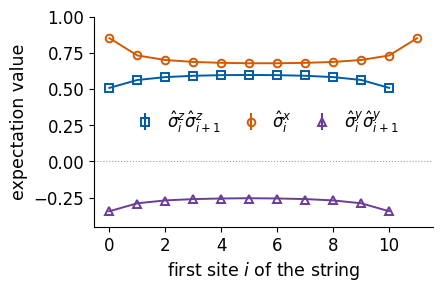

In [18]:
def pauli_local_from_inputs(p, sigma, u, string):
    # equation (23d): string = {site: "X" | "Y" | "Z"}; signs of the Z and Y sites times the ratio (23b) with F = X and Y sites
    factor = np.ones(len(sigma), dtype=complex)
    for i, op in string.items():
        if op == "Z":
            factor = factor * sigma[:, i]
        if op == "Y":
            factor = factor * (-1j) * sigma[:, i]
    F = [i for i, op in string.items() if op in "XY"]
    return factor * ratio_from_inputs(p, sigma, u, F)

for label, string in (("Z_0 Z_1", {0: "Z", 1: "Z"}), ("X_0", {0: "X"}), ("Y_0 Y_1", {0: "Y", 1: "Y"})):
    print(f"three spins, snapshot 001, {label}: local value {pauli_local_from_inputs(p_three, s_three, u_three, string)[0].real:+.3f}")

u_snap = hidden_inputs(p_ref, flat)                                     # inputs of all recorded snapshots, computed once, shape (204800, M)
# check (may be skipped): the same local values as pauli_local, which evaluates the network afresh for every flipped configuration
for name in ("X_5", "Y_5 Y_6"):
    diff = np.max(np.abs(pauli_local_from_inputs(p_ref, flat, u_snap, STRINGS[name]) - pauli_local(p_ref, flat, STRINGS[name])))
    print(f"{name}: largest difference from pauli_local over all snapshots {diff:.0e}")

CHAIN_STRINGS = {"ZZ": lambda i: {i: "Z", i + 1: "Z"}, "X": lambda i: {i: "X"}, "YY": lambda i: {i: "Y", i + 1: "Y"}}
CHAIN_PAULI = {}                                                        # rows (i, sampled mean, error, exact) for each kind of string
for kind, make in CHAIN_STRINGS.items():
    rows = []
    for i in range(N - len(make(0)) + 1):                               # 11 bonds for the two-site strings, 12 sites for X
        values = pauli_local_from_inputs(p_ref, flat, u_snap, make(i)).real.reshape(RECORD, CHAINS)
        mean, err = binned(values, L_BIN)
        exact_value = float((psi_ref @ (pauli_matrix(make(i)) @ psi_ref)).real)
        rows.append((i, mean, err, exact_value))
    CHAIN_PAULI[kind] = np.array(rows)
print("  i    <Z_i Z_i+1> sampled, exact      <X_i> sampled, exact          <Y_i Y_i+1> sampled, exact")
for i in range(N):
    line = f"  {i:2d}"
    for kind in ("ZZ", "X", "YY"):
        if i < len(CHAIN_PAULI[kind]):
            _, m_, e_, x_ = CHAIN_PAULI[kind][i]
            line += f"   {m_:+.4f} +- {e_:.4f}  {x_:+.4f}"
        else:
            line += " " * 31
    print(line)
dev_chain = max(float(np.max(np.abs(v[:, 1] - v[:, 3]) / v[:, 2])) for v in CHAIN_PAULI.values())
print(f"largest deviation from the exact sum, in units of the statistical error, over all "
      f"{sum(len(v) for v in CHAIN_PAULI.values())} strings: {dev_chain:.1f}")

# --- figure (drawing code may be skipped) ---
def draw_chain_strings(ax):
    for kind, c, mk, lab in (("ZZ", COL["blue"], "s", r"$\hat\sigma^z_i\hat\sigma^z_{i+1}$"), ("X", COL["rbm"], "o", r"$\hat\sigma^x_i$"),
                             ("YY", COL["sampled"], "^", r"$\hat\sigma^y_i\hat\sigma^y_{i+1}$")):
        v = CHAIN_PAULI[kind]
        ax.plot(v[:, 0], v[:, 3], color=c, lw=1.4)
        ax.errorbar(v[:, 0], v[:, 1], yerr=v[:, 2], fmt=mk, color=c, ms=5.5, mfc="none", mew=1.4, label=lab)
    ax.axhline(0, color=COL["grey"], lw=0.8, ls=":")
    ax.set_xticks(range(0, N, 2)); ax.set_xlabel("first site $i$ of the string"); ax.set_ylabel("expectation value")
    ax.set_ylim(-0.45, 1.0); ax.legend(frameon=False, ncol=3, loc="center", columnspacing=0.8, handletextpad=0.3)
one_panel("fig_lab080_pauli_chain", draw_chain_strings)
time_core = time.perf_counter() - started
print(f"\ncore route (Sections 1 to 6): {time_core:.1f} s")

The ratios from the hidden inputs give the same local values as `pauli_local` to rounding, and the three local values of the three-spin network are those of the table above. The figure shows the three expectation values against the first site $i$ of the string, sampled (symbols with errors) and exact (lines). All 34 sampled values agree with the exact sums of the same network, with a largest deviation of 2.4 statistical errors, and all of them come from one set of $z$ snapshots. The correlation of neighbours along $z$ is weakest at the two ends, where the transverse magnetisation is largest. The correlation $\langle\hat\sigma^y_i\hat\sigma^y_{i+1}\rangle$ is negative everywhere, because its local value carries the factor $-\sigma_i\sigma_{i+1}$, which is negative on the many snapshots in which the two neighbours agree.

The core route ends here, and the last line of the output above gives its measured runtime.

## 7. Summary

The restricted Boltzmann machine of the energy-based models becomes a wave function when its Boltzmann weight, summed over the hidden units, is read as an amplitude. The visible units are the physical spins, and with hidden units $\pm1$ the sum factorises into one hyperbolic cosine per hidden unit, equation (11). A visible bias acts like a field on its spin, a hidden unit acts like a ferromagnetic coupling among the spins it connects and, on four or more spins, also adds couplings of more than two spins, and the network stores $N+M+NM$ numbers in place of $2^N$ amplitudes. For the transverse-field Ising chain all off-diagonal matrix elements are non-positive, so the ground state has positive amplitudes and real parameters suffice.

The energy of the state is the average of the local energy over the Born probabilities of the snapshots. The coupling strings of the Hamiltonian contribute their values $\sigma_i\sigma_{i+1}$ on a snapshot, and the field strings contribute ratios of amplitudes of configurations one flip apart. At an eigenstate every snapshot has the same local energy, which two spins showed in Section 5 and the narrow distribution of the local energy of the trained network showed in Section 6. The Metropolis algorithm samples the snapshots with ratios of squared amplitudes, so neither the normalisation nor the hidden units are ever needed. For the network such a ratio follows from the inputs of the hidden units already computed for the snapshot, at a cost of $|F|\cdot M$ operations for $|F|$ flipped spins. Snapshots of a network with twelve hidden units reproduced the distribution of the total spin, the correlation function, the expectation values of single- and two-site Pauli strings including those with $\hat\sigma^x$ and $\hat\sigma^y$, and the energy, all within errors obtained from binning.

Lab 081 fits the same network to measured bit strings and bounds the entanglement depth of the measured state.

## 8. Exercises

1. Derive equation (12) and show that a network with hidden units $h_j\in\{0,1\}$ gives the factor $1+e^{u_j}$. Substitute $h_j=(1+h_j')/2$ with $h_j'=\pm1$ and find the hidden biases and weights of the $\pm1$ network that give the same amplitudes up to a constant factor.
2. Take the configuration of six spins in the local-energy sketch, $\mathbf s=011001$, and the network with all parameters zero. Compute the coupling part and the field part of the local energy (16), then explain why the average of the local energy over all configurations is $-gN$.
3. For two spins at $g=2J$, repeat the calculation of equations (18) and (19) and compare the resulting energy with the lowest eigenvalue of the $4\times4$ matrix.
4. The strings along the chain in Section 6 give a larger $\langle\hat\sigma^x_0\rangle$ at the edge of the chain than $\langle\hat\sigma^x_5\rangle$ in its middle, and a smaller $\langle\hat\sigma^z_0\hat\sigma^z_1\rangle$. Explain both with the open boundary, from the number of bonds that hold an edge spin.
5. For $N=100$ sites, compare the number of amplitudes $2^N$ with the number of parameters of an RBM with $M=N$. Count the multiplications of the ratio (23b) for one flipped spin and compare them with those of a new amplitude (11).
6. Repeat the sampling of Section 6 for the trained network with 128 recorded sweeps in place of 2048. Compare the errors of the sampled energy and of $\langle\hat\sigma^x_5\rangle$ with those of the recorded run, and check that they grow by about the factor $\sqrt{2048/128}=4$.

## References

[1] G. Carleo and M. Troyer, Solving the quantum many-body problem with artificial neural networks, Science **355**, 602 (2017), doi:10.1126/science.aag2302.

[2] P. Pfeuty, The one-dimensional Ising model with a transverse field, Ann. Phys. **57**, 79 (1970), doi:10.1016/0003-4916(70)90270-8.

[3] P. Virtanen *et al.*, SciPy 1.0: fundamental algorithms for scientific computing in Python, Nat. Methods **17**, 261 (2020), doi:10.1038/s41592-019-0686-2.

[4] N. Metropolis, A. W. Rosenbluth, M. N. Rosenbluth, A. H. Teller and E. Teller, Equation of state calculations by fast computing machines, J. Chem. Phys. **21**, 1087 (1953), doi:10.1063/1.1699114.

The last cell writes every number quoted in the text to the results file and to the macro file, and prints the measured runtimes.

In [19]:
# --- bookkeeping (may be skipped): every recorded number to JSON and to the LaTeX macro file ---
summary = dict(
    experiment="RBM wave function with real parameters for the open transverse-field Ising chain (N = 12): amplitude, induced couplings, "
               "local energy, Metropolis sampling of snapshots with local estimators of Pauli strings for a trained network whose parameters "
               "are read from data/rbm_tfim_N12_M12_params.npz (trained in advance by exact-sum energy minimisation); JAX float64 on CPU",
    model=dict(N=N, J=J, fields=[float(x) for x in EXACT], hamiltonian="-J sum Z_i Z_{i+1} - g sum X_i, open chain"),
    checks=dict(hidden_sum_max_relative_difference=check_hidden, energy_all_parameters_zero=E_zero,
                energy_local_vs_matrix=[E_local, E_matrix], two_spins_E0=E0_two, two_spins_r=float(r_star)),
    exact={str(g): dict(E0=e["E0"], gap=e["gap"], correlations_s0_sr=e["C"].tolist()) for g, e in EXACT.items()},
    loaded_network=dict(file="data/rbm_tfim_N12_M12_params.npz", hidden_units=M_MAIN, parameters=n_params,
                        energy_exact_sum=E_loaded, relative_energy_error=(E_loaded - ex["E0"]) / abs(ex["E0"]), fidelity=F_loaded),
    sampling=dict(chains=CHAINS, burn_in_sweeps=BURN, recorded_sweeps=RECORD, bin_length=L_BIN,
                  acceptance={k_: v_["acc"] for k_, v_ in SNAP.items()},
                  pauli_strings_sites_5_6=PAULI_CHECK,
                  correlations_sampled=C_samp.tolist(), correlations_exact_same_network=C_exact_ref.tolist(),
                  energy={k_: dict(coupling_part=v_["zz"], field_part=v_["x"], total=v_["total"], exact_coupling=v_["exact_zz"],
                                   exact_field=v_["exact_x"], exact_total=v_["exact"], sigma_local_energy=v_["sigma_loc"])
                          for k_, v_ in ENERGY.items()},
                  binning_errors_trained={k_: dict(zip(map(str, L_LIST), v_)) for k_, v_ in BIN_ERR.items()},
                  total_spin_squared=dict(sampled=m2_mean, error=m2_err, exact=m2_exact),
                  pauli_strings_along_chain={k_: v_.tolist() for k_, v_ in CHAIN_PAULI.items()}),
    runtime_seconds=dict(core_sections_1_6=time_core, sampling=time_sampling, total=time.perf_counter() - started))
NUMBERS.update(RuntimeCore=f"{time_core:.0f}")
(RES / "lab080_results.json").write_text(json.dumps(summary, indent=2))
with open(FIG / "nb_numbers_lab080.tex", "w") as f:
    f.write("% numbers of Lab 080 (Lecture 15 version, N = 12 transverse-field Ising chain); prefix \\labeightyNQS\n")
    for k_, v_ in NUMBERS.items():
        f.write(f"\\newcommand{{\\labeightyNQS{k_}}}{{{v_.strip()}}}\n")
print("numbers:", NUMBERS)
print(f"runtime: Sections 1-6 {time_core:.1f} s, total {summary['runtime_seconds']['total']:.1f} s")
print("written: classroom_results/lab080_results.json, figures/nb_numbers_lab080.tex and the figures figures/fig_lab080_*")

numbers: {'N': '12', 'Dim': '4096', 'EZero': '-14.9260', 'Gap': '0.251', 'AmpMin': '7.1\\times10^{-4}', 'AmpMax': '0.254', 'COne': '0.51', 'CLast': '0.08', 'SmallN': '4', 'SmallM': '3', 'SmallParams': '19', 'HiddenSumCheck': '4\\times10^{-16}', 'ConfigsFifty': '1.1\\times10^{15}', 'ConfigsHundred': '1.3\\times10^{30}', 'MemoryFifty': '9.0\\times10^{15}', 'RStar': '0.618', 'EZeroTwo': '-2.2361', 'EnergyUniform': '-12', 'DemoPAligned': '0.362', 'DemoPAnti': '0.138', 'DemoCumTwo': '0.500', 'DemoCumThree': '0.638', 'DemoRSq': '0.382', 'DemoProposals': '4000', 'DemoRecorded': '2000', 'DemoWalkAligned': '0.365', 'DemoWalkAnti': '0.135', 'HiddenMain': '12', 'ParamsMain': '168', 'SampledChains': '100', 'SampledBurn': '500', 'SampledSweeps': '2048', 'BinLength': '32', 'SampledSnapshots': '204800', 'AcceptTrained': '0.38', 'PauliXSampled': '0.6794', 'PauliXError': '0.0021', 'PauliXExact': '0.6775', 'PauliYImagSampled': '0.0018', 'PauliYImagError': '0.0028', 'EnergyZZSampled': '-6.269', 'EnergyZZ